# 2. Campaign Effectiveness


## 2.1 Database Connection

In [1]:
import pandas as pd

from getpass import getpass
from sqlalchemy import create_engine, text, URL

In [2]:
db_url = URL.create(
    drivername="postgresql+psycopg2",
    username="postgres",
    password=getpass("PostgreSQL password: "),
    host="localhost",
    port=5432,
    database="retail_promotion_db"
)

engine = create_engine(db_url)


# Execute SQL queries and return pandas DataFrames
def read_query(sql):
    with engine.connect() as connection:
        return pd.read_sql_query(text(sql), connection)

## 2.2 Campaign Overview

In [3]:
# Summarize campaign characteristics
campaign_overview = read_query("""
    SELECT
        c.campaign,
        c.description AS campaign_type,
        c.start_day,
        c.end_day,
        c.end_day - c.start_day + 1 AS duration_days,
        COUNT(a.household_key) AS assigned_households
    FROM analytics.dim_campaign AS c
    LEFT JOIN analytics.fact_campaign_assignment AS a
        ON c.campaign = a.campaign
    GROUP BY
        c.campaign,
        c.description,
        c.start_day,
        c.end_day
    ORDER BY c.start_day;
""")

display(campaign_overview)

,campaign,campaign_type,start_day,end_day,duration_days,assigned_households
0,26,TypeA,224,264,41,332
1,27,TypeC,237,300,64,12
2,28,TypeB,259,320,62,17
3,29,TypeB,281,334,54,118
4,30,TypeA,323,369,47,361
5,1,TypeB,346,383,38,13
6,2,TypeB,351,383,33,48
7,3,TypeC,356,412,57,12
8,4,TypeB,372,404,33,81
9,5,TypeB,377,411,35,166


In [4]:
# Check campaign duration and household assignment totals
print("Campaigns:", len(campaign_overview))
print("Campaign types:")
print(campaign_overview["campaign_type"].value_counts())
print("\nTotal household assignments:", campaign_overview["assigned_households"].sum())
print("\nCampaign duration:")

print(campaign_overview["duration_days"].describe())

Campaigns: 30
Campaign types:
campaign_type
TypeB    19
TypeC     6
TypeA     5
Name: count, dtype: int64

Total household assignments: 7208

Campaign duration:
count     30.000000
mean      47.600000
std       24.856277
min       33.000000
25%       33.000000
50%       38.500000
75%       55.500000
max      162.000000
Name: duration_days, dtype: float64


## 2.3 Observation Periods

In [5]:
# Identify the available transaction observation period
observation_period = read_query("""
    SELECT
        MIN(day) AS first_day,
        MAX(day) AS last_day
    FROM analytics.fact_sales;
""")

display(observation_period)

,first_day,last_day
0,1,711


In [6]:
# Define the boundaries of the available observation period
first_day = int(observation_period.loc[0, "first_day"])
last_day = int(observation_period.loc[0, "last_day"])

# Calculate observed days before, during and after campaigns
campaign_overview["before_days"] = (campaign_overview["start_day"] - first_day).clip(lower=0)

campaign_overview["during_days"] = (campaign_overview["end_day"].clip(upper=last_day) - campaign_overview["start_day"].clip(lower=first_day) + 1).clip(lower=0)

campaign_overview["after_days"] = (last_day - campaign_overview["end_day"]).clip(lower=0)

# Identify campaigns with incomplete transaction coverage
campaign_overview["full_campaign_observed"] = (campaign_overview["duration_days"] == campaign_overview["during_days"])

print(campaign_overview)

    campaign campaign_type  start_day  end_day  duration_days  \
0         26         TypeA        224      264             41   
1         27         TypeC        237      300             64   
2         28         TypeB        259      320             62   
3         29         TypeB        281      334             54   
4         30         TypeA        323      369             47   
5          1         TypeB        346      383             38   
6          2         TypeB        351      383             33   
7          3         TypeC        356      412             57   
8          4         TypeB        372      404             33   
9          5         TypeB        377      411             35   
10         6         TypeC        393      425             33   
11         7         TypeB        398      432             35   
12         8         TypeA        412      460             49   
13         9         TypeB        435      467             33   
14        10         Type

## 2.4 Household Purchasing Behaviour

In [7]:
# Aggregate household purchases across all campaign periods
household_campaign_sales = read_query("""
    SELECT
        a.household_key,
        a.campaign,
        c.description AS campaign_type,
        COALESCE(SUM(s.sales_value) FILTER (WHERE s.day < c.start_day), 0) AS sales_before,
        COALESCE(SUM(s.sales_value) FILTER (WHERE s.day BETWEEN c.start_day AND c.end_day), 0) AS sales_during,
        COALESCE(SUM(s.sales_value) FILTER (WHERE s.day > c.end_day), 0) AS sales_after,
        COUNT(DISTINCT s.basket_id) FILTER (WHERE s.day < c.start_day) AS baskets_before,
        COUNT(DISTINCT s.basket_id) FILTER (WHERE s.day BETWEEN c.start_day AND c.end_day) AS baskets_during,
        COUNT(DISTINCT s.basket_id) FILTER (WHERE s.day > c.end_day) AS baskets_after
    FROM analytics.fact_campaign_assignment AS a
    JOIN analytics.dim_campaign AS c
        ON a.campaign = c.campaign
    LEFT JOIN analytics.fact_sales AS s
        ON a.household_key = s.household_key
    GROUP BY
        a.household_key,
        a.campaign,
        c.description;
""")

print(household_campaign_sales.head(10))

   household_key  campaign campaign_type  sales_before  sales_during  \
0              1         8         TypeA       2198.56        429.01   
1              1        12         TypeB       2775.65        205.41   
2              1        13         TypeA       2941.16        209.97   
3              1        18         TypeA       3362.46        465.67   
4              1        20         TypeC       3612.54        426.44   
5              1        22         TypeB       3701.91        167.79   
6              1        23         TypeB       3828.13        210.85   
7              1        29         TypeB       1426.47        301.36   
8              2        18         TypeA       1621.59        201.86   
9              3         8         TypeA       2160.80        121.54   

   sales_after  baskets_before  baskets_during  baskets_after  
0      1702.59              41               7             38  
1      1349.10              51               6             29  
2      1179.03 

In [8]:
# Add campaign duration and observation period lengths
household_campaign_sales = household_campaign_sales.merge(
    campaign_overview[
        [
            "campaign",
            "duration_days",
            "before_days",
            "during_days",
            "after_days",
            "full_campaign_observed"
        ]
    ],
    on="campaign",
    how="left",
    validate="many_to_one"
)

# Distinguish unavailable periods from zero recorded purchases
for period in ["before", "during", "after"]:
    columns = [f"sales_{period}", f"baskets_{period}"]

    household_campaign_sales.loc[
        household_campaign_sales[f"{period}_days"] == 0,
        columns
    ] = float("nan")

print(household_campaign_sales.head(10))

   household_key  campaign campaign_type  sales_before  sales_during  \
0              1         8         TypeA       2198.56        429.01   
1              1        12         TypeB       2775.65        205.41   
2              1        13         TypeA       2941.16        209.97   
3              1        18         TypeA       3362.46        465.67   
4              1        20         TypeC       3612.54        426.44   
5              1        22         TypeB       3701.91        167.79   
6              1        23         TypeB       3828.13        210.85   
7              1        29         TypeB       1426.47        301.36   
8              2        18         TypeA       1621.59        201.86   
9              3         8         TypeA       2160.80        121.54   

   sales_after  baskets_before  baskets_during  baskets_after  duration_days  \
0      1702.59            41.0             7.0           38.0             49   
1      1349.10            51.0             6.0 

In [9]:
# Calculate standardized purchasing activity metrics
for period in ["before", "during", "after"]:
    days = household_campaign_sales[f"{period}_days"].replace(0, float("nan"))
    sales = household_campaign_sales[f"sales_{period}"]
    baskets = household_campaign_sales[f"baskets_{period}"]
    household_campaign_sales[f"weekly_sales_{period}"] = (sales / days * 7)
    household_campaign_sales[f"weekly_baskets_{period}"] = (baskets / days * 7    )
    household_campaign_sales[f"avg_basket_value_{period}"] = (sales / baskets.replace(0, float("nan"))    )

print(household_campaign_sales.head(10))

   household_key  campaign campaign_type  sales_before  sales_during  \
0              1         8         TypeA       2198.56        429.01   
1              1        12         TypeB       2775.65        205.41   
2              1        13         TypeA       2941.16        209.97   
3              1        18         TypeA       3362.46        465.67   
4              1        20         TypeC       3612.54        426.44   
5              1        22         TypeB       3701.91        167.79   
6              1        23         TypeB       3828.13        210.85   
7              1        29         TypeB       1426.47        301.36   
8              2        18         TypeA       1621.59        201.86   
9              3         8         TypeA       2160.80        121.54   

   sales_after  baskets_before  baskets_during  baskets_after  duration_days  \
0      1702.59            41.0             7.0           38.0             49   
1      1349.10            51.0             6.0 

In [10]:
# Validate the household-campaign dataset
print("Rows:", len(household_campaign_sales))
print("Duplicate household-campaign pairs:", household_campaign_sales.duplicated(["household_key", "campaign"]).sum())
print("Campaigns with incomplete coverage:",(~campaign_overview["full_campaign_observed"]).sum())
print("Assignments without post-campaign observations:",(household_campaign_sales["after_days"] == 0).sum())

Rows: 7208
Duplicate household-campaign pairs: 0
Campaigns with incomplete coverage: 1
Assignments without post-campaign observations: 100


In [11]:
# Calculate changes in weekly sales
household_campaign_sales["weekly_sales_change_during"] = (household_campaign_sales["weekly_sales_during"] - household_campaign_sales["weekly_sales_before"])
household_campaign_sales["weekly_sales_change_after"] = (household_campaign_sales["weekly_sales_after"] - household_campaign_sales["weekly_sales_before"])

# Calculate changes in weekly basket frequency
household_campaign_sales["weekly_baskets_change_during"] = (household_campaign_sales["weekly_baskets_during"] - household_campaign_sales["weekly_baskets_before"])
household_campaign_sales["weekly_baskets_change_after"] = (household_campaign_sales["weekly_baskets_after"] - household_campaign_sales["weekly_baskets_before"])

# Calculate changes in average basket value
household_campaign_sales["avg_basket_value_change_during"] = (household_campaign_sales["avg_basket_value_during"] - household_campaign_sales["avg_basket_value_before"])
household_campaign_sales["avg_basket_value_change_after"] = (household_campaign_sales["avg_basket_value_after"] - household_campaign_sales["avg_basket_value_before"])

In [12]:
# Summarize purchasing behaviour by campaign
campaign_performance = (
    household_campaign_sales
    .groupby(["campaign", "campaign_type"], as_index=False)
    .agg(
        avg_weekly_sales_before=("weekly_sales_before", "mean"),
        avg_weekly_sales_during=("weekly_sales_during", "mean"),
        avg_weekly_sales_after=("weekly_sales_after", "mean"),
        mean_sales_change=("weekly_sales_change_during", "mean"),
        median_sales_change=("weekly_sales_change_during", "median"),
        mean_sales_change_after=("weekly_sales_change_after", "mean"),
        mean_baskets_change=("weekly_baskets_change_during", "mean"),
        mean_basket_value_change=("avg_basket_value_change_during", "mean")
    )
)

# Add campaign characteristics
campaign_performance = campaign_performance.merge(
    campaign_overview,
    on=["campaign", "campaign_type"],
    how="left",
    validate="one_to_one"
)

In [13]:
# Calculate relative changes in mean weekly sales
campaign_performance["sales_change_pct"] = (100 * campaign_performance["mean_sales_change"] / campaign_performance["avg_weekly_sales_before"].replace(0, float("nan")))

print(
    campaign_performance[
        [
            "campaign",
            "campaign_type",
            "duration_days",
            "assigned_households",
            "avg_weekly_sales_before",
            "avg_weekly_sales_during",
            "avg_weekly_sales_after",
            "mean_sales_change",
            "median_sales_change",
            "sales_change_pct"
        ]
    ]
    .sort_values("sales_change_pct", ascending=False)
    .round(2)
)

    campaign campaign_type  duration_days  assigned_households  \
28        29         TypeB             54                  118   
4          5         TypeB             35                  166   
3          4         TypeB             33                   81   
5          6         TypeC             33                   65   
18        19         TypeB             33                  130   
6          7         TypeB             35                  198   
20        21         TypeB             33                   65   
11        12         TypeB             33                  170   
8          9         TypeB             33                  176   
7          8         TypeA             49                 1076   
19        20         TypeC             71                  244   
17        18         TypeA             56                 1133   
22        23         TypeB             39                  183   
1          2         TypeB             33                   48   
0         

## 2.5 Campaign Type Comparison

In [14]:
# Compare campaign characteristics across campaign types
campaign_type_structure = (
    campaign_overview
    .groupby("campaign_type")
    .agg(
        campaigns=("campaign", "count"),
        household_assignments=("assigned_households", "sum"),
        mean_households=("assigned_households", "mean"),
        mean_duration=("duration_days", "mean"),
        median_duration=("duration_days", "median"),
        min_duration=("duration_days", "min"),
        max_duration=("duration_days", "max")
    )
)

print(campaign_type_structure.round(2))

               campaigns  household_assignments  mean_households  \
campaign_type                                                      
TypeA                  5                   3979           795.80   
TypeB                 19                   2655           139.74   
TypeC                  6                    574            95.67   

               mean_duration  median_duration  min_duration  max_duration  
campaign_type                                                              
TypeA                  48.20             48.0            41            56  
TypeB                  38.63             33.0            33            62  
TypeC                  75.50             65.0            33           162  


In [15]:
# Compare campaign types at the household-assignment level
type_by_assignment = (
    household_campaign_sales
    .groupby("campaign_type")
    .agg(
        assignments=("campaign", "size"),
        unique_households=("household_key", "nunique"),
        mean_sales_change=("weekly_sales_change_during", "mean"),
        median_sales_change=("weekly_sales_change_during", "median"),
        mean_baskets_change=("weekly_baskets_change_during", "mean")
    )
)

print(type_by_assignment.round(2))

               assignments  unique_households  mean_sales_change  \
campaign_type                                                      
TypeA                 3979               1513               7.50   
TypeB                 2655               1023              12.01   
TypeC                  574                397              10.33   

               median_sales_change  mean_baskets_change  
campaign_type                                            
TypeA                         3.87                 0.18  
TypeB                         8.93                 0.23  
TypeC                         8.23                 0.06  


In [16]:
# Compare campaign types with equal campaign weights
type_by_campaign = (
    campaign_performance
    .groupby("campaign_type")
    .agg(
        campaigns=("campaign", "count"),
        mean_sales_change=("mean_sales_change", "mean"),
        median_sales_change=("mean_sales_change", "median"),
        mean_sales_change_pct=("sales_change_pct", "mean"),
        mean_baskets_change=("mean_baskets_change", "mean")
    )
)

print(type_by_campaign.round(2))

               campaigns  mean_sales_change  median_sales_change  \
campaign_type                                                      
TypeA                  5               6.81                 6.55   
TypeB                 19              10.84                10.78   
TypeC                  6               4.48                 6.83   

               mean_sales_change_pct  mean_baskets_change  
campaign_type                                              
TypeA                          13.97                 0.14  
TypeB                          17.68                 0.21  
TypeC                           5.87                -0.05  


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent visualization style
plt.style.use("default")

sns.set_theme(
    style="whitegrid",
    palette="muted",
    font_scale=1.1,
    rc={
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white"
    }
)

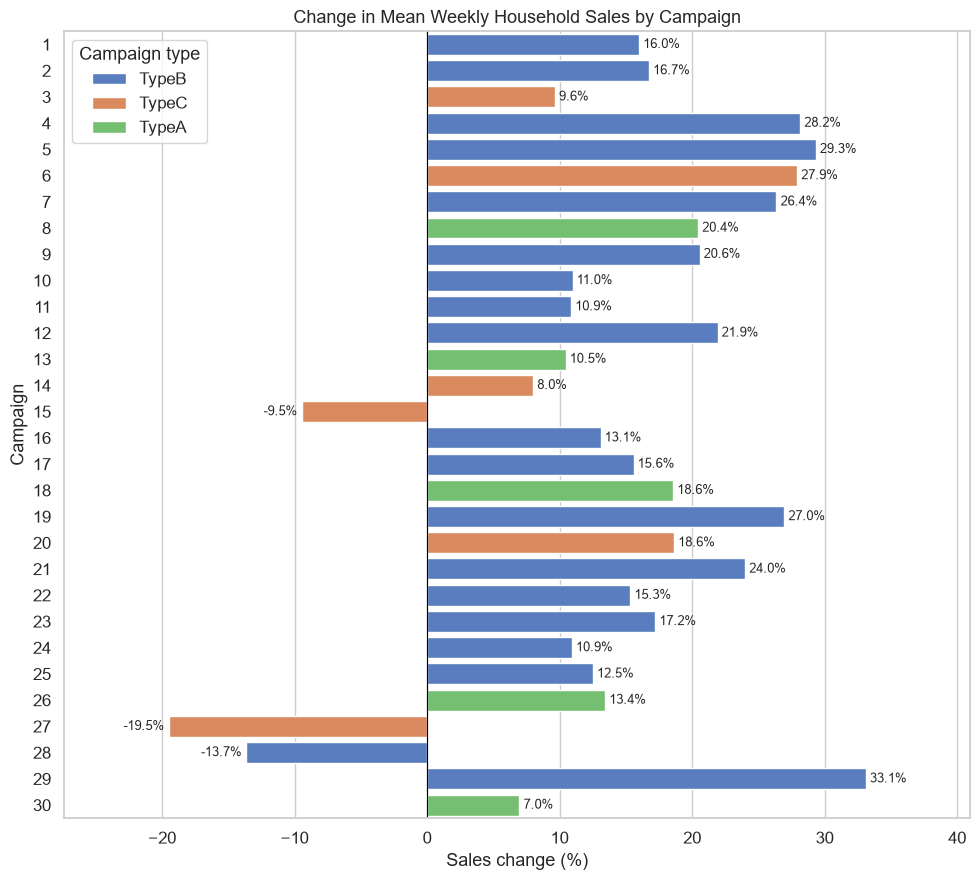

In [18]:
# Visualize relative sales changes across campaigns
plt.figure(figsize=(10, 9))

ax = sns.barplot(
    data=campaign_performance.sort_values(
        "sales_change_pct", ascending=False
    ),
    x="sales_change_pct",
    y="campaign",
    hue="campaign_type",
    orient="h",
    dodge=False,
    errorbar=None
)

# Add percentage labels to bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Change in Mean Weekly Household Sales by Campaign")
plt.xlabel("Sales change (%)")
plt.ylabel("Campaign")
plt.legend(title="Campaign type")
plt.margins(x=0.15)
plt.tight_layout()
plt.show()

In [19]:
# Prepare campaign type comparison data
type_comparison = pd.DataFrame({
    "Assignment-weighted": type_by_assignment["mean_sales_change"],
    "Campaign-weighted": type_by_campaign["mean_sales_change"]
})

type_comparison = (
    type_comparison.reset_index()
    .melt(
        id_vars="campaign_type",
        var_name="weighting_method",
        value_name="sales_change"
    )
)

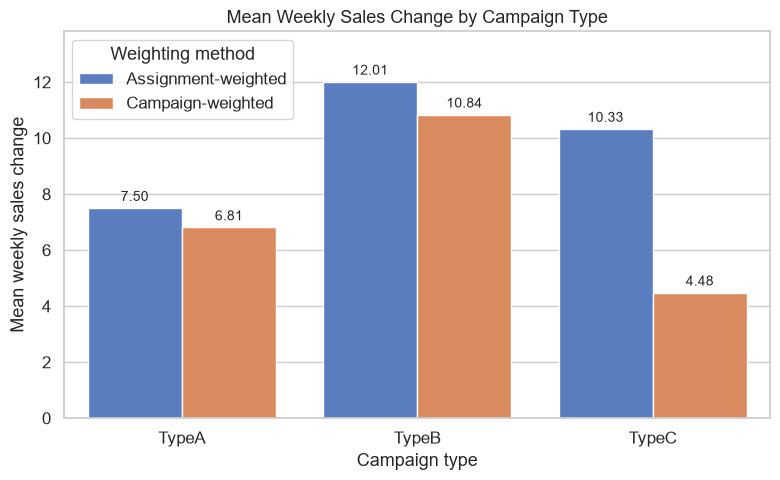

In [20]:
# Compare campaign types by weighting method
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=type_comparison,
    x="campaign_type",
    y="sales_change",
    hue="weighting_method",
    errorbar=None
)

# Add value labels to bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=10)

plt.title("Mean Weekly Sales Change by Campaign Type")
plt.xlabel("Campaign type")
plt.ylabel("Mean weekly sales change")
plt.legend(title="Weighting method")
plt.margins(y=0.15)
plt.tight_layout()
plt.show()

## 2.6 Overall Sales Trend

In [21]:
# Aggregate observed sales by week
weekly_sales = read_query("""
    SELECT
        d.week_no,
        COUNT(DISTINCT d.day) AS observed_days,
        SUM(s.sales_value) AS total_sales
    FROM analytics.dim_day AS d
    LEFT JOIN analytics.fact_sales AS s
        ON d.day = s.day
    WHERE d.week_no IS NOT NULL
    GROUP BY d.week_no
    ORDER BY d.week_no;
""")

# Standardize sales to seven-day periods
weekly_sales["standardized_sales"] = (weekly_sales["total_sales"] / weekly_sales["observed_days"] * 7
)

# Calculate a four-week moving average
weekly_sales["moving_average"] = (weekly_sales["standardized_sales"].rolling(4).mean())

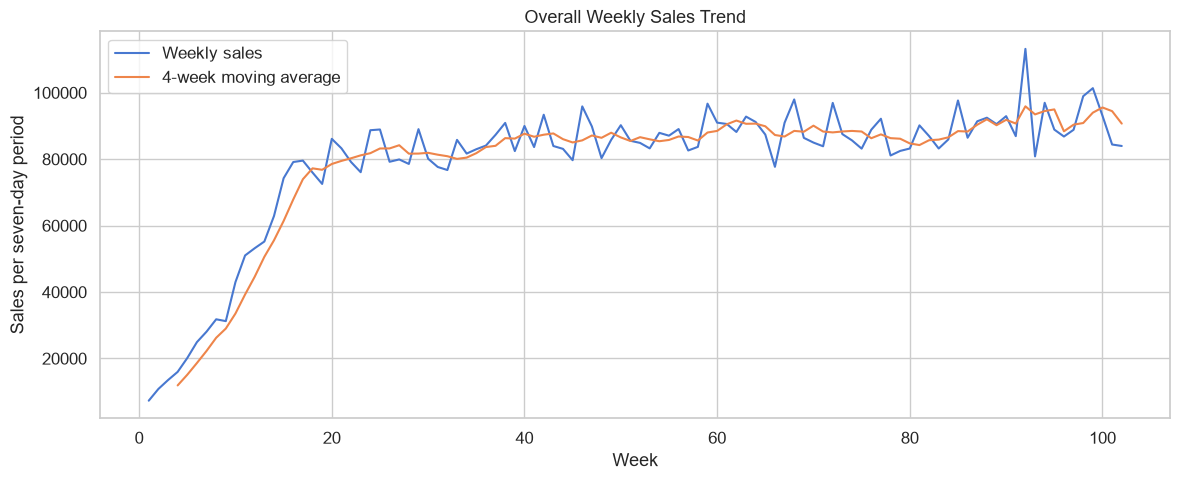

In [22]:
# Visualize weekly sales and the moving average
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=weekly_sales,
    x="week_no",
    y="standardized_sales",
    label="Weekly sales"
)

sns.lineplot(
    data=weekly_sales,
    x="week_no",
    y="moving_average",
    label="4-week moving average"
)

plt.title("Overall Weekly Sales Trend")
plt.xlabel("Week")
plt.ylabel("Sales per seven-day period")
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
# Aggregate observed sales and household activity by week
weekly_sales = read_query("""
    SELECT
        d.week_no,
        COUNT(DISTINCT d.day) AS observed_days,
        COUNT(DISTINCT s.household_key) AS active_households,
        SUM(s.sales_value) AS total_sales
    FROM analytics.dim_day AS d
    LEFT JOIN analytics.fact_sales AS s
        ON d.day = s.day
    WHERE d.week_no IS NOT NULL
    GROUP BY d.week_no
    ORDER BY d.week_no;
""")

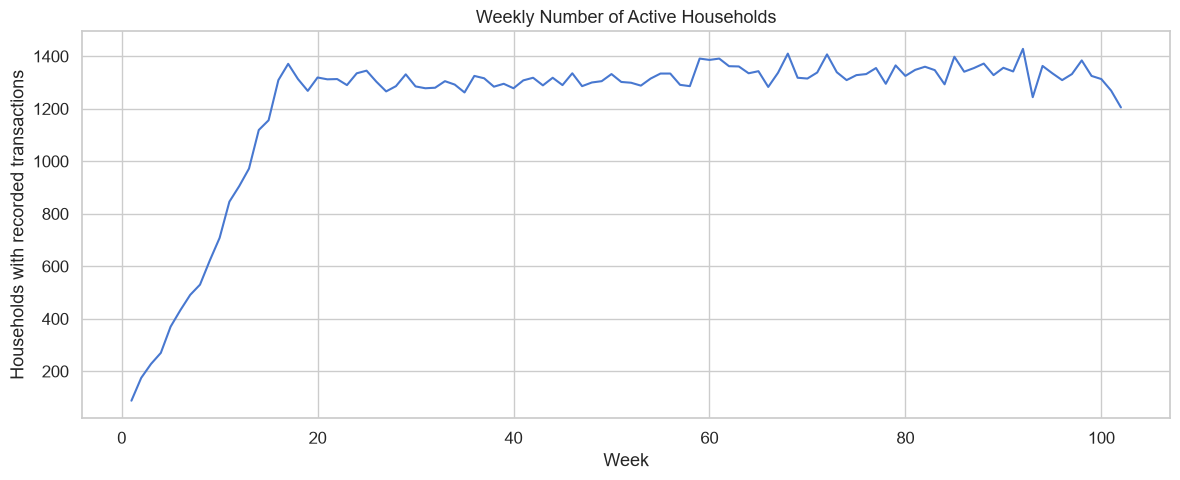

In [24]:
# Visualize weekly household activity
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=weekly_sales,
    x="week_no",
    y="active_households"
)

plt.title("Weekly Number of Active Households")
plt.xlabel("Week")
plt.ylabel("Households with recorded transactions")
plt.tight_layout()
plt.show()

In [25]:
# Calculate weekly sales per active household
weekly_sales["sales_per_active_household"] = (weekly_sales["total_sales"] / weekly_sales["active_households"])

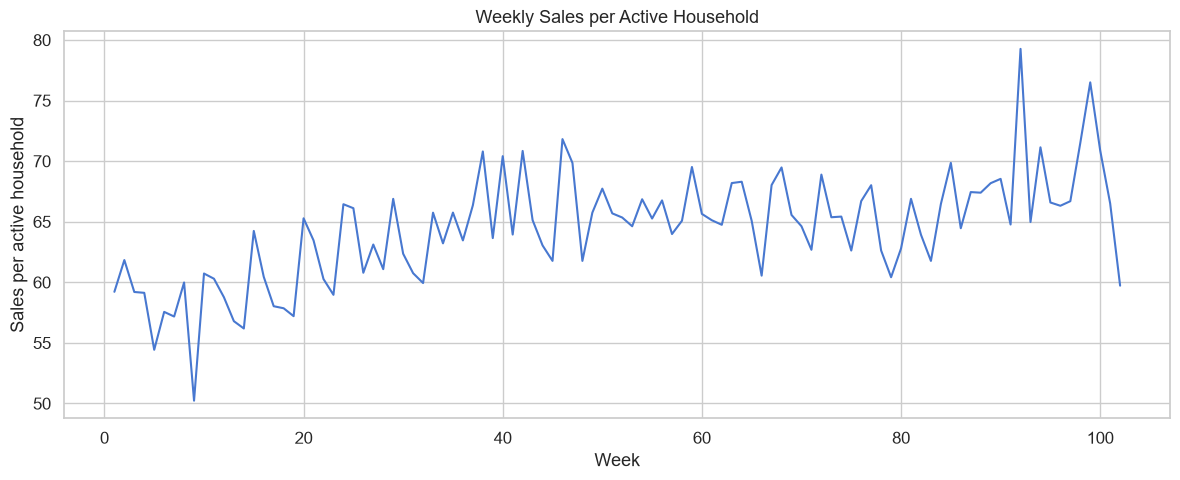

In [26]:
# Visualize sales per active household over time
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=weekly_sales,
    x="week_no",
    y="sales_per_active_household"
)

plt.title("Weekly Sales per Active Household")
plt.xlabel("Week")
plt.ylabel("Sales per active household")
plt.tight_layout()
plt.show()

In [27]:
# Identify the first recorded transaction week for each household
household_first_week = read_query("""
    SELECT
        s.household_key,
        MIN(d.week_no) AS first_week
    FROM analytics.fact_sales AS s
    JOIN analytics.dim_day AS d
        ON s.day = d.day
    GROUP BY s.household_key;
""")

print(household_first_week["first_week"].describe())

count    2500.00000
mean       10.11520
std         5.60165
min         1.00000
25%         6.00000
50%        11.00000
75%        14.00000
max        97.00000
Name: first_week, dtype: float64


In [28]:
# Count households by their first recorded transaction week
new_households = (
    household_first_week
    .groupby("first_week")
    .size()
    .reset_index(name="households")
)

print(new_households)

    first_week  households
0            1          88
1            2         129
2            3         113
3            4         118
4            5         138
5            6         119
6            7         131
7            8         132
8            9         129
9           10         140
10          11         179
11          12         171
12          13         152
13          14         166
14          15         167
15          16         197
16          17         194
17          18          28
18          19           1
19          20           1
20          23           1
21          31           1
22          32           1
23          40           1
24          63           1
25          88           1
26          97           1


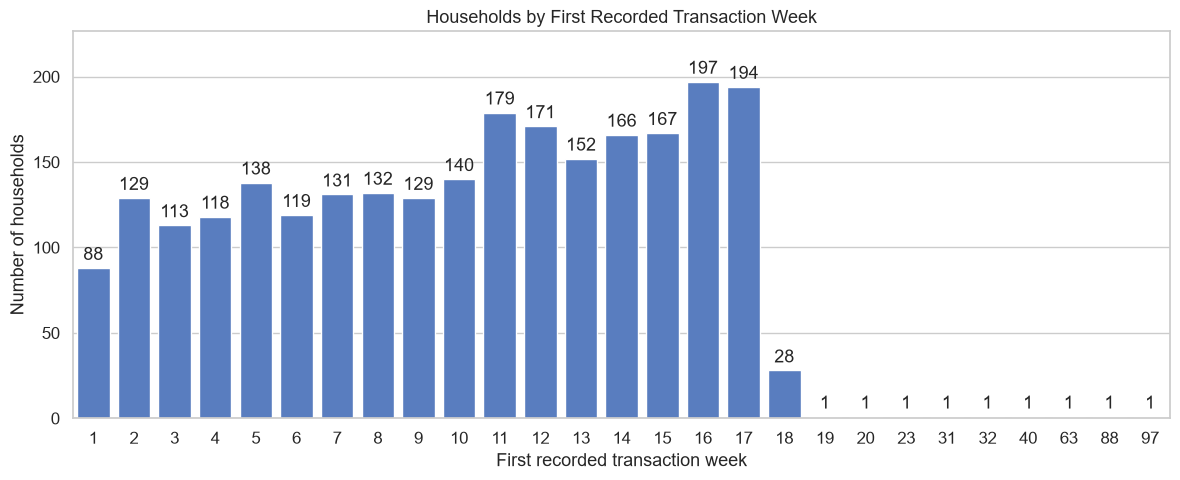

In [29]:
# Visualize first recorded transaction weeks
plt.figure(figsize=(12, 5))

ax = sns.barplot(
    data=new_households,
    x="first_week",
    y="households",
    color=sns.color_palette("muted")[0],
    errorbar=None
)

ax.bar_label(ax.containers[0], fmt="%d", padding=3)

plt.title("Households by First Recorded Transaction Week")
plt.xlabel("First recorded transaction week")
plt.ylabel("Number of households")
plt.margins(y=0.15)
plt.tight_layout()
plt.show()

In [30]:
print(weekly_sales.columns.tolist())

['week_no', 'observed_days', 'active_households', 'total_sales', 'sales_per_active_household']


In [31]:
# Standardize sales to seven-day periods
weekly_sales["standardized_sales"] = (
    weekly_sales["total_sales"]
    / weekly_sales["observed_days"] * 7
)

# Calculate a four-week moving average
weekly_sales["moving_average"] = (
    weekly_sales["standardized_sales"]
    .rolling(4)
    .mean()
)

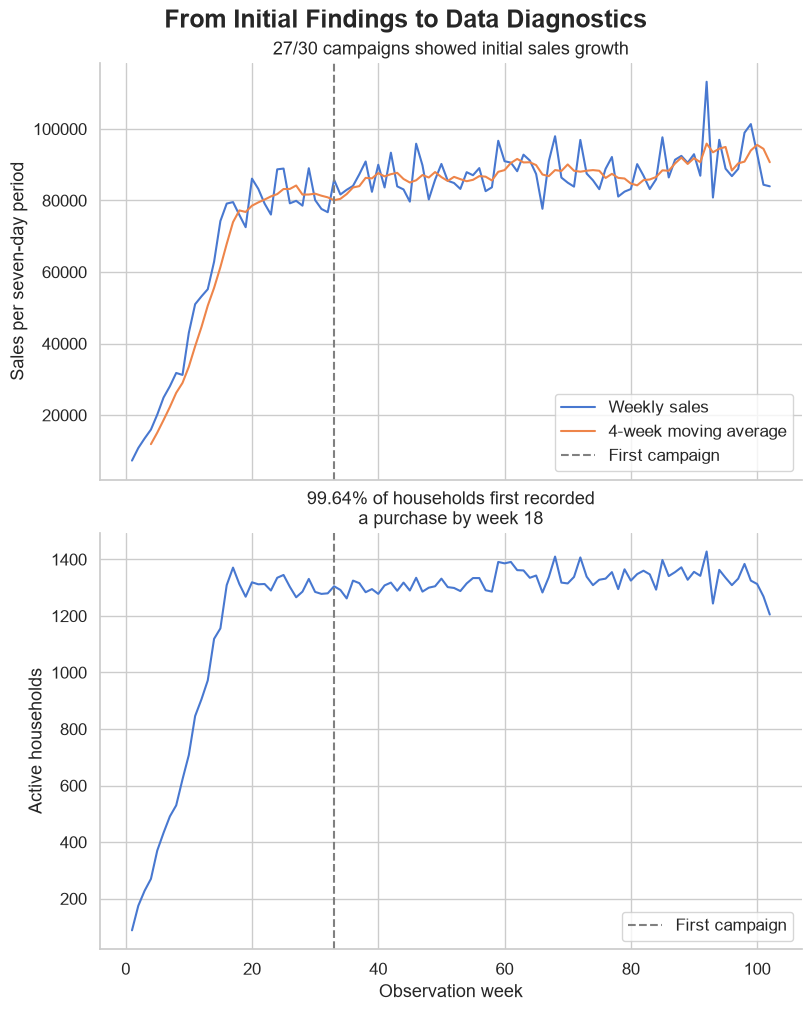

In [32]:
# Calculate key diagnostic indicators
positive_campaigns = (
    campaign_performance["sales_change_pct"] > 0
).sum()

early_households_pct = (
    household_first_week["first_week"].le(18).mean() * 100
)

first_campaign_week = weekly_sales.loc[
    weekly_sales["observed_days"].cumsum()
    >= campaign_overview["start_day"].min(),
    "week_no"
].iloc[0]

# Combine sales trend and household activity
fig, axes = plt.subplots(
    2, 1,
    figsize=(8, 10),
    sharex=True,
    layout="constrained"
)

sns.lineplot(
    data=weekly_sales,
    x="week_no",
    y="standardized_sales",
    label="Weekly sales",
    ax=axes[0]
)

sns.lineplot(
    data=weekly_sales,
    x="week_no",
    y="moving_average",
    label="4-week moving average",
    ax=axes[0]
)

axes[0].axvline(
    first_campaign_week,
    color="gray",
    linestyle="--",
    label="First campaign"
)

axes[0].set_title(
    f"{positive_campaigns}/30 campaigns showed initial sales growth"
)
axes[0].set_ylabel("Sales per seven-day period")
axes[0].legend()

# Visualize household activity
sns.lineplot(
    data=weekly_sales,
    x="week_no",
    y="active_households",
    ax=axes[1]
)

axes[1].axvline(
    first_campaign_week,
    color="gray",
    linestyle="--",
    label="First campaign"
)

axes[1].set_title(
    f"{early_households_pct:.2f}% of households first recorded\n"
    "a purchase by week 18"
)

axes[1].set_xlabel("Observation week")
axes[1].set_ylabel("Active households")
axes[1].legend()

fig.suptitle(
    "From Initial Findings to Data Diagnostics",
    fontsize=18,
    fontweight="bold"
)

sns.despine()
plt.show()

## 2.7 Product Category Analysis

In [33]:
# Aggregate category sales before, during and after campaigns
category_sales = read_query("""
    SELECT
        a.campaign,
        p.department,
        p.commodity_desc,
        COALESCE(SUM(s.sales_value) FILTER (WHERE s.day < c.start_day), 0) AS sales_before,
        COALESCE(SUM(s.sales_value) FILTER (WHERE s.day BETWEEN c.start_day AND c.end_day), 0) AS sales_during,
        COALESCE(SUM(s.sales_value) FILTER (WHERE s.day > c.end_day), 0) AS sales_after
    FROM analytics.fact_campaign_assignment AS a
    JOIN analytics.dim_campaign AS c
        ON a.campaign = c.campaign
    JOIN analytics.fact_sales AS s
        ON a.household_key = s.household_key
    JOIN analytics.dim_product AS p
        ON s.product_id = p.product_id
    GROUP BY
        a.campaign,
        p.department,
        p.commodity_desc;
""")

print(category_sales.head(10))

   campaign      department                commodity_desc  sales_before  \
0         1                                                        0.00   
1         1       COSMETICS                          BATH          0.00   
2         1       COSMETICS          COSMETIC ACCESSORIES          0.00   
3         1       COSMETICS                    FRAGRANCES         39.99   
4         1       COSMETICS          MAKEUP AND TREATMENT         49.37   
5         1  COUP/STR & MFG           COUPONS/STORE & MFG          3.49   
6         1            DELI                       CHEESES         97.42   
7         1            DELI               CHICKEN/POULTRY         51.72   
8         1            DELI                    DELI MEATS        254.66   
9         1            DELI  DELI SPECIALTIES (RETAIL PK)          5.35   

   sales_during  sales_after  
0          0.00         0.00  
1          0.00        12.96  
2          0.00        17.99  
3          0.00        45.00  
4         20.20    

In [34]:
# Retrieve all product categories
categories = read_query("""
    SELECT DISTINCT
        department,
        commodity_desc
    FROM analytics.dim_product;
""")

# Create all campaign-category combinations
category_performance = campaign_overview.merge(categories, how="cross")

# Add recorded category sales
category_performance = category_performance.merge(
    category_sales,
    on=["campaign", "department", "commodity_desc"],
    how="left",
    validate="one_to_one"
)

# Fill missing recorded sales with zero
sales_columns = [
    "sales_before",
    "sales_during",
    "sales_after"
]

category_performance[sales_columns] = (category_performance[sales_columns].fillna(0))

# Mark unavailable post-campaign periods
category_performance.loc[category_performance["after_days"] == 0,"sales_after"] = float("nan")

print("Rows:", len(category_performance))

Rows: 10800


In [35]:
# Calculate weekly category sales per assigned household
category_performance["weekly_sales_before"] = (
    category_performance["sales_before"]
    / category_performance["before_days"]
    / category_performance["assigned_households"]
    * 7
)

category_performance["weekly_sales_during"] = (
    category_performance["sales_during"]
    / category_performance["during_days"]
    / category_performance["assigned_households"]
    * 7
)

category_performance["weekly_sales_after"] = (
    category_performance["sales_after"]
    / category_performance["after_days"].replace(0, float("nan"))
    / category_performance["assigned_households"]
    * 7
)

In [36]:
# Calculate absolute and relative category sales changes
category_performance["sales_change"] = (category_performance["weekly_sales_during"] - category_performance["weekly_sales_before"])
category_performance["sales_change_pct"] = (100 * category_performance["sales_change"] / category_performance["weekly_sales_before"].replace(0, float("nan")))
category_performance["sales_change_after"] = (category_performance["weekly_sales_after"] - category_performance["weekly_sales_before"])

In [37]:
# Validate category sales against household-level totals
category_totals = (
    category_performance
    .groupby("campaign")[sales_columns]
    .sum(min_count=1)
)

household_totals = (
    household_campaign_sales
    .groupby("campaign")[sales_columns]
    .sum(min_count=1)
)

print(
    (category_totals - household_totals)
    .abs()
    .max()
    .round(6)
)

sales_before    0.0
sales_during    0.0
sales_after     0.0
dtype: float64


In [38]:
# Inspect category-level campaign results
print(
    category_performance[
        [
            "campaign",
            "campaign_type",
            "department",
            "commodity_desc",
            "weekly_sales_before",
            "weekly_sales_during",
            "weekly_sales_after",
            "sales_change",
            "sales_change_pct"
        ]
    ]
    .round(2)
    .head(20)
)

    campaign campaign_type       department          commodity_desc  \
0         26         TypeA        COSMETICS    MAKEUP AND TREATMENT   
1         26         TypeA  CHARITABLE CONT                 UNKNOWN   
2         26         TypeA               RX       COUPON/MISC ITEMS   
3         26         TypeA       MEAT-PCKGD              HEAT/SERVE   
4         26         TypeA          GROCERY     FRZN JCE CONC/DRNKS   
5         26         TypeA               RX                PHARMACY   
6         26         TypeA             MEAT                   BACON   
7         26         TypeA           FLORAL             EASTER LILY   
8         26         TypeA          GROCERY  FRZN MEAT/MEAT DINNERS   
9         26         TypeA          PRODUCE                POTATOES   
10        26         TypeA           FLORAL        FLORAL-FRESH CUT   
11        26         TypeA          DRUG GM       HARDWARE SUPPLIES   
12        26         TypeA        NUTRITION              RICE CAKES   
13    

In [39]:
# Summarize category sales by campaign type
category_type_performance = (
    category_performance
    .groupby(
        ["campaign_type", "department", "commodity_desc"],
        as_index=False,
        dropna=False
    )
    .agg(
        campaigns=("campaign", "nunique"),
        avg_weekly_sales_before=("weekly_sales_before", "mean"),
        avg_weekly_sales_during=("weekly_sales_during", "mean"),
        avg_weekly_sales_after=("weekly_sales_after", "mean"),
        mean_sales_change=("sales_change", "mean")
    )
)

# Calculate relative changes in mean weekly sales
category_type_performance["sales_change_pct"] = (
    100
    * category_type_performance["mean_sales_change"]
    / category_type_performance["avg_weekly_sales_before"].where(
        category_type_performance["avg_weekly_sales_before"] > 0
    )
)

print("Rows:", len(category_type_performance))
print(category_type_performance.head(10))

Rows: 1080
  campaign_type       department        commodity_desc  campaigns  \
0         TypeA                                                 5   
1         TypeA       AUTOMOTIVE                COUPON          5   
2         TypeA       AUTOMOTIVE             NEWSPAPER          5   
3         TypeA  CHARITABLE CONT               UNKNOWN          5   
4         TypeA      CHEF SHOPPE               UNKNOWN          5   
5         TypeA  CNTRL/STORE SUP     COUPON/MISC ITEMS          5   
6         TypeA        COSMETICS                  BATH          5   
7         TypeA        COSMETICS  COSMETIC ACCESSORIES          5   
8         TypeA        COSMETICS     COUPON/MISC ITEMS          5   
9         TypeA        COSMETICS            FRAGRANCES          5   

   avg_weekly_sales_before  avg_weekly_sales_during  avg_weekly_sales_after  \
0                 0.000000                 0.000000                0.000000   
1                 0.002825                 0.003753                0.00

In [40]:
# Identify categories with the highest baseline sales
top_categories = (
    category_performance
    .groupby(
        ["department", "commodity_desc"],
        as_index=False
    )
    .agg(
        baseline_sales=("weekly_sales_before", "mean")
    )
    .nlargest(15, "baseline_sales")
)

print(top_categories.round(2))

          department          commodity_desc  baseline_sales
234        KIOSK-GAS       COUPON/MISC ITEMS            4.39
222          GROCERY             SOFT DRINKS            2.47
238             MEAT                    BEEF            2.41
176          GROCERY     FLUID MILK PRODUCTS            1.60
155          GROCERY                  CHEESE            1.53
186          GROCERY  FRZN MEAT/MEAT DINNERS            1.26
139          GROCERY              BAG SNACKS            1.15
180          GROCERY            FROZEN PIZZA            1.14
140          GROCERY  BAKED BREAD/BUNS/ROLLS            1.14
146          GROCERY              BEERS/ALES            1.00
17              DELI              DELI MEATS            0.92
158          GROCERY             COLD CEREAL            0.90
239             MEAT                 CHICKEN            0.79
262  MISC SALES TRAN       COUPON/MISC ITEMS            0.79
44           DRUG GM              CIGARETTES            0.70


In [41]:
# Select categories for visualization
category_comparison = category_type_performance.merge(
    top_categories,
    on=["department", "commodity_desc"],
    how="inner",
    validate="many_to_one"
)

# Create unique category labels
category_comparison["category"] = (category_comparison["department"] + " / " + category_comparison["commodity_desc"])

# Reshape absolute sales changes for visualization
category_heatmap = category_comparison.pivot(
    index="category",
    columns="campaign_type",
    values="mean_sales_change"
)

print(category_heatmap.round(2))

campaign_type                        TypeA  TypeB  TypeC
category                                                
DELI / DELI MEATS                     0.04   0.08   0.11
DRUG GM / CIGARETTES                  0.05   0.00   0.10
GROCERY / BAG SNACKS                  0.09   0.24   0.02
GROCERY / BAKED BREAD/BUNS/ROLLS      0.09   0.18  -0.04
GROCERY / BEERS/ALES                  0.03   0.06  -0.05
GROCERY / CHEESE                      0.19   0.29   0.16
GROCERY / COLD CEREAL                 0.09   0.14  -0.02
GROCERY / FLUID MILK PRODUCTS         0.20   0.29  -0.01
GROCERY / FROZEN PIZZA                0.07   0.08  -0.02
GROCERY / FRZN MEAT/MEAT DINNERS      0.20   0.24   0.30
GROCERY / SOFT DRINKS                 0.17   0.15  -0.19
KIOSK-GAS / COUPON/MISC ITEMS         0.60   1.39   1.30
MEAT / BEEF                           0.09   0.43   0.17
MEAT / CHICKEN                        0.01   0.05  -0.10
MISC SALES TRAN / COUPON/MISC ITEMS   0.20   0.12   0.23


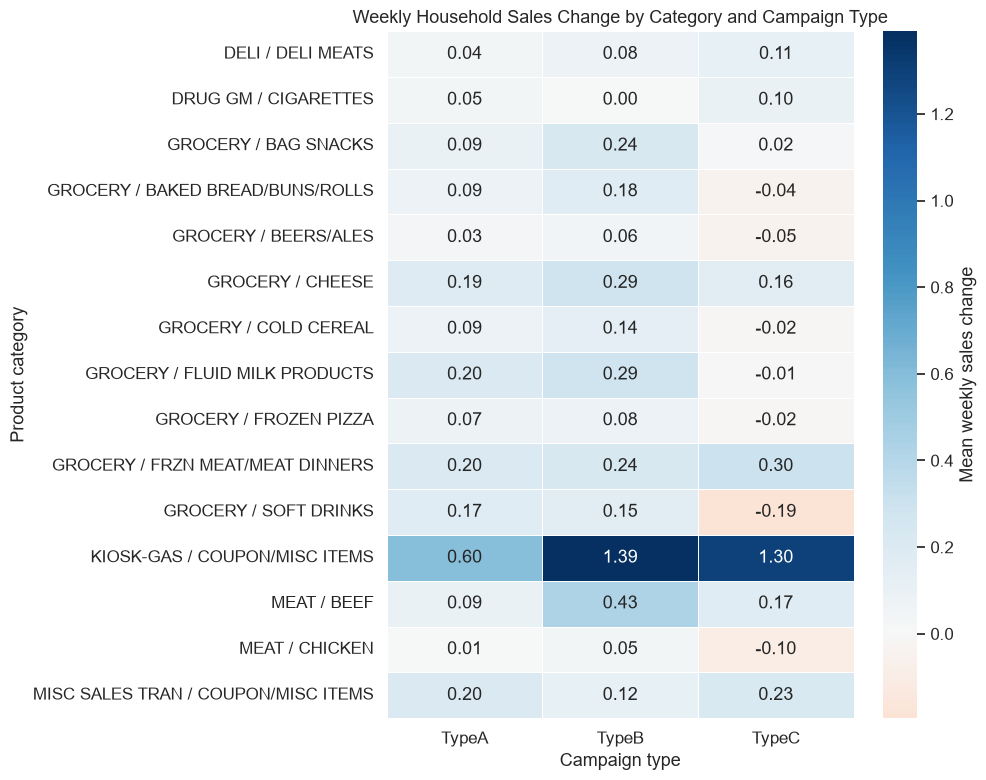

In [42]:
# Visualize absolute sales changes by category and campaign type
plt.figure(figsize=(10, 8))

sns.heatmap(
    category_heatmap,
    annot=True,
    fmt=".2f",
    cmap="RdBu",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Mean weekly sales change"}
)

plt.title("Weekly Household Sales Change by Category and Campaign Type")
plt.xlabel("Campaign type")
plt.ylabel("Product category")
plt.tight_layout()
plt.show()

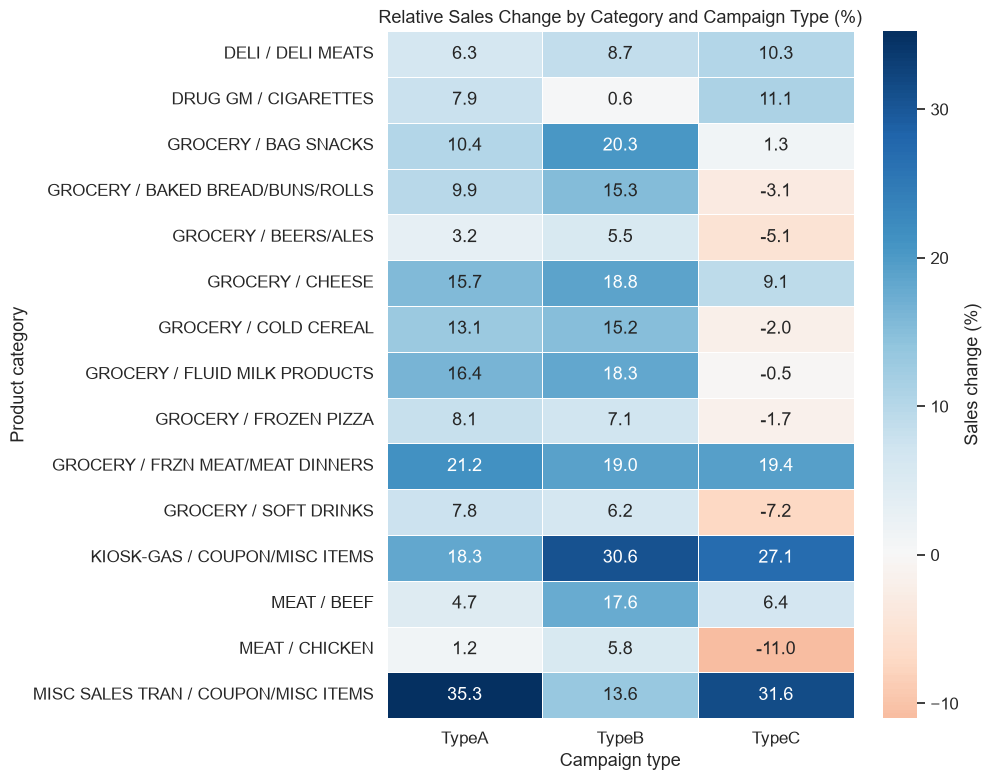

In [43]:
# Reshape relative sales changes for visualization
category_heatmap_pct = category_comparison.pivot(
    index="category",
    columns="campaign_type",
    values="sales_change_pct"
)

# Visualize relative sales changes by category and campaign type
plt.figure(figsize=(10, 8))

sns.heatmap(
    category_heatmap_pct,
    annot=True,
    fmt=".1f",
    cmap="RdBu",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Sales change (%)"}
)

plt.title("Relative Sales Change by Category and Campaign Type (%)")
plt.xlabel("Campaign type")
plt.ylabel("Product category")
plt.tight_layout()
plt.show()

## 2.8 Campaign Duration Analysis

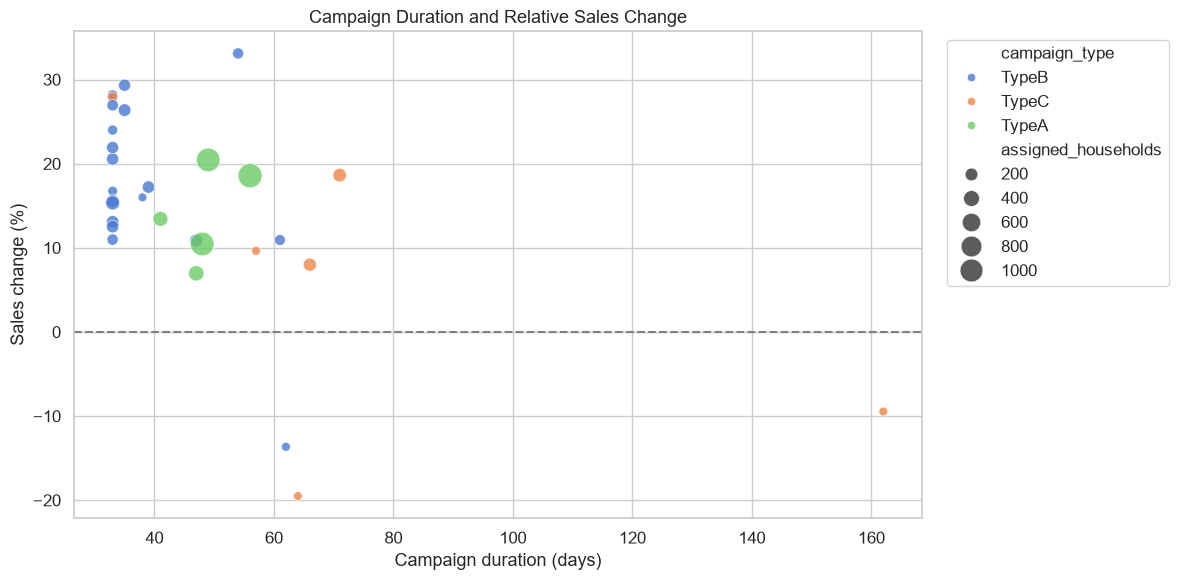

In [44]:
# Visualize the relationship between campaign duration and sales change
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=campaign_performance,
    x="duration_days",
    y="sales_change_pct",
    hue="campaign_type",
    size="assigned_households",
    sizes=(40, 300),
    alpha=0.8
)

plt.axhline(0, color="gray", linestyle="--")
plt.title("Campaign Duration and Relative Sales Change")
plt.xlabel("Campaign duration (days)")
plt.ylabel("Sales change (%)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [45]:
# Calculate Spearman correlations between campaign characteristics and outcomes
duration_correlation = campaign_performance[
    [
        "duration_days",
        "assigned_households",
        "mean_sales_change",
        "sales_change_pct"
    ]
].corr(method="spearman")

print(duration_correlation.round(3))

                     duration_days  assigned_households  mean_sales_change  \
duration_days                1.000                0.016             -0.574   
assigned_households          0.016                1.000              0.001   
mean_sales_change           -0.574                0.001              1.000   
sales_change_pct            -0.498                0.029              0.882   

                     sales_change_pct  
duration_days                  -0.498  
assigned_households             0.029  
mean_sales_change               0.882  
sales_change_pct                1.000  


In [46]:
# Calculate duration-sales correlations within campaign types
duration_by_type = (
    campaign_performance
    .groupby("campaign_type")[
        ["duration_days", "sales_change_pct"]
    ]
    .corr(method="spearman")
)

print(duration_by_type.round(3))

                                duration_days  sales_change_pct
campaign_type                                                  
TypeA         duration_days             1.000             0.600
              sales_change_pct          0.600             1.000
TypeB         duration_days             1.000            -0.189
              sales_change_pct         -0.189             1.000
TypeC         duration_days             1.000            -0.429
              sales_change_pct         -0.429             1.000


In [47]:
# Assess sensitivity to the longest campaign
duration_sensitivity = pd.DataFrame({
    "All campaigns": campaign_performance[
        ["duration_days", "sales_change_pct"]
    ].corr(method="spearman")["duration_days"],

    "Without campaign 15": campaign_performance.loc[
        campaign_performance["campaign"] != 15,
        ["duration_days", "sales_change_pct"]
    ].corr(method="spearman")["duration_days"]
})

print(duration_sensitivity.round(3))

                  All campaigns  Without campaign 15
duration_days             1.000                1.000
sales_change_pct         -0.498               -0.446


In [48]:
# Calculate duration-sales correlations by product category
category_duration = (
    category_performance
    .groupby(["department", "commodity_desc"])[
        ["duration_days", "sales_change"]
    ]
    .corr(method="spearman")
    .xs("duration_days", level=-1)
    .reset_index()
    .rename(columns={"sales_change": "spearman_rho"})
)

category_duration = category_duration.drop(columns="duration_days")

print(category_duration.head(15))

         department        commodity_desc  spearman_rho
0                                                   NaN
1        AUTOMOTIVE                COUPON      0.008518
2        AUTOMOTIVE             NEWSPAPER           NaN
3   CHARITABLE CONT               UNKNOWN     -0.075792
4       CHEF SHOPPE               UNKNOWN     -0.353715
5   CNTRL/STORE SUP     COUPON/MISC ITEMS     -0.054706
6         COSMETICS                  BATH     -0.252034
7         COSMETICS  COSMETIC ACCESSORIES     -0.010579
8         COSMETICS     COUPON/MISC ITEMS      0.006331
9         COSMETICS            FRAGRANCES      0.063497
10        COSMETICS  MAKEUP AND TREATMENT      0.056110
11   COUP/STR & MFG   COUPONS/STORE & MFG      0.141654
12       DAIRY DELI                  EGGS     -0.038867
13       DAIRY DELI      MILK BY-PRODUCTS           NaN
14             DELI               CHEESES     -0.482912


In [49]:
# Select the same baseline categories for visualization
category_duration_top = category_duration.merge(
    top_categories,
    on=["department", "commodity_desc"],
    how="inner",
    validate="one_to_one"
)

# Create unique category labels
category_duration_top["category"] = (category_duration_top["department"] + " / " + category_duration_top["commodity_desc"])

print(category_duration_top.round(3))

         department          commodity_desc  spearman_rho  baseline_sales  \
0              DELI              DELI MEATS        -0.226           0.924   
1           DRUG GM              CIGARETTES        -0.005           0.704   
2           GROCERY              BAG SNACKS        -0.372           1.150   
3           GROCERY  BAKED BREAD/BUNS/ROLLS        -0.523           1.141   
4           GROCERY              BEERS/ALES        -0.117           1.002   
5           GROCERY                  CHEESE        -0.246           1.531   
6           GROCERY             COLD CEREAL        -0.130           0.901   
7           GROCERY     FLUID MILK PRODUCTS        -0.458           1.599   
8           GROCERY            FROZEN PIZZA        -0.036           1.141   
9           GROCERY  FRZN MEAT/MEAT DINNERS        -0.075           1.259   
10          GROCERY             SOFT DRINKS        -0.339           2.474   
11        KIOSK-GAS       COUPON/MISC ITEMS        -0.243           4.386   

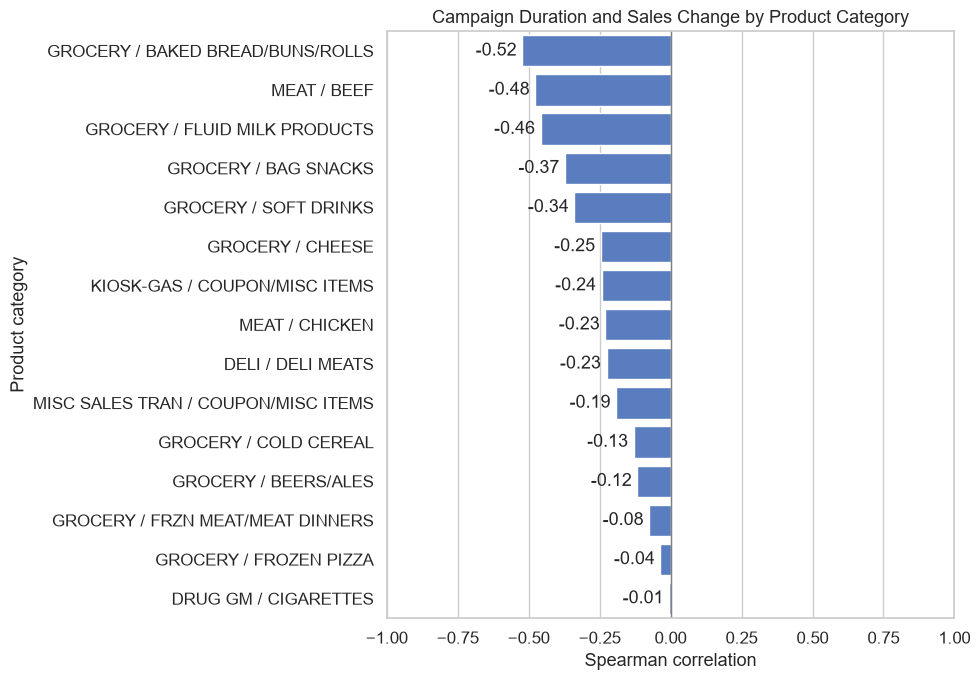

In [50]:
# Visualize duration-sales correlations across categories
plt.figure(figsize=(10, 7))

ax = sns.barplot(
    data=category_duration_top.sort_values("spearman_rho"),
    x="spearman_rho",
    y="category",
    color=sns.color_palette("muted")[0],
    errorbar=None
)

# Add correlation labels
ax.bar_label(
    ax.containers[0],
    fmt="%+.2f",
    padding=4
)

plt.axvline(0, color="gray", linewidth=1)
plt.xlim(-1, 1)
plt.title("Campaign Duration and Sales Change by Product Category")
plt.xlabel("Spearman correlation")
plt.ylabel("Product category")
plt.tight_layout()
plt.show()

## 2.9 Discount Intensity Analysis

In [51]:
# Aggregate realized discounts by campaign and product category
discount_by_category = read_query("""
    SELECT
        a.campaign,
        p.department,
        p.commodity_desc,
        SUM(s.sales_value) AS total_sales,
        -SUM(s.retail_disc) AS retail_discount,
        -SUM(s.coupon_disc) AS coupon_discount,
        -SUM(s.coupon_match_disc) AS coupon_match_discount
    FROM analytics.fact_campaign_assignment AS a
    JOIN analytics.dim_campaign AS c
        ON a.campaign = c.campaign
    JOIN analytics.fact_sales AS s
        ON a.household_key = s.household_key
       AND s.day BETWEEN c.start_day AND c.end_day
    JOIN analytics.dim_product AS p
        ON s.product_id = p.product_id
    GROUP BY
        a.campaign,
        p.department,
        p.commodity_desc;
""")

display(discount_by_category.head(10))

,campaign,department,commodity_desc,total_sales,retail_discount,coupon_discount,coupon_match_discount
0,1,,,0.00,0.00,15.75,0.00
1,1,COSMETICS,MAKEUP AND TREATMENT,20.20,7.19,0.00,0.00
2,1,DELI,CHEESES,5.93,1.19,0.00,0.00
3,1,DELI,CHICKEN/POULTRY,3.04,0.34,0.00,0.00
4,1,DELI,DELI MEATS,34.30,4.04,0.00,0.00
5,1,DELI,PREPARED FOOD,1.25,0.00,0.00,0.00
6,1,DELI,SALADS/DIPS,7.37,1.20,0.55,0.45
7,1,DELI,SNACKS,5.98,0.00,0.00,0.00
8,1,DRUG GM,BABY FOODS,10.92,0.00,0.00,0.00
9,1,DRUG GM,BABY HBC,3.99,0.00,0.00,0.00


In [52]:
# Summarize realized discounts by campaign
campaign_discounts = (
    discount_by_category
    .groupby("campaign", as_index=False)
    .agg(
        total_sales=("total_sales", "sum"),
        retail_discount=("retail_discount", "sum"),
        coupon_discount=("coupon_discount", "sum"),
        coupon_match_discount=("coupon_match_discount", "sum")
    )
)

# Calculate total discount and reconstructed gross sales
campaign_discounts["total_discount"] = (campaign_discounts["retail_discount"] + campaign_discounts["coupon_discount"] + campaign_discounts["coupon_match_discount"])
campaign_discounts["gross_sales"] = (campaign_discounts["total_sales"] + campaign_discounts["retail_discount"] + campaign_discounts["coupon_match_discount"])

# Calculate overall discount intensity
campaign_discounts["discount_rate"] = (100 * campaign_discounts["total_discount"] / campaign_discounts["gross_sales"].where(campaign_discounts["gross_sales"] > 0))

print(campaign_discounts.round(2))

    campaign  total_sales  retail_discount  coupon_discount  \
0          1      3753.24           892.48            40.80   
1          2     11595.22          2504.46           140.00   
2          3      8557.36          1559.53            61.20   
3          4     26521.71          4359.35           173.99   
4          5     71934.00         11359.80           416.29   
5          6     31595.26          4731.57           252.52   
6          7     73966.46         11816.37           504.96   
7          8    422789.31         75228.44          2843.16   
8          9     47715.29          8192.79           357.05   
9         10     44519.48          7444.71           389.18   
10        11    105789.63         18095.34           693.55   
11        12     64819.41         10775.59           246.75   
12        13    416088.88         70809.17          3166.66   
13        14    169778.32         27430.78          1130.23   
14        15     20022.50          3211.70            6

In [53]:
# Combine discount intensity with campaign performance
discount_analysis = campaign_performance.merge(
    campaign_discounts,
    on="campaign",
    how="left",
    validate="one_to_one"
)

print(
    discount_analysis[
        [
            "campaign",
            "campaign_type",
            "duration_days",
            "discount_rate",
            "mean_sales_change",
            "sales_change_pct"
        ]
    ]
    .sort_values("discount_rate", ascending=False)
    .round(2)
)

    campaign campaign_type  duration_days  discount_rate  mean_sales_change  \
0          1         TypeB             38          20.22               7.33   
1          2         TypeB             33          18.88               7.35   
26        27         TypeC             64          16.50             -17.63   
2          3         TypeC             57          16.17               7.70   
25        26         TypeA             41          16.00               6.55   
29        30         TypeA             47          15.98               3.44   
27        28         TypeB             62          15.87             -11.90   
24        25         TypeB             33          15.87              10.78   
7          8         TypeA             49          15.75               9.53   
19        20         TypeC             71          15.66              13.69   
16        17         TypeB             33          15.57              10.47   
8          9         TypeB             33          1

In [54]:
# Examine correlations between duration, discounts and sales changes
discount_correlation = discount_analysis[
    [
        "duration_days",
        "discount_rate",
        "mean_sales_change",
        "sales_change_pct"
    ]
].corr(method="spearman")

print(discount_correlation.round(3))

                   duration_days  discount_rate  mean_sales_change  \
duration_days              1.000          0.171             -0.574   
discount_rate              0.171          1.000             -0.584   
mean_sales_change         -0.574         -0.584              1.000   
sales_change_pct          -0.498         -0.475              0.882   

                   sales_change_pct  
duration_days                -0.498  
discount_rate                -0.475  
mean_sales_change             0.882  
sales_change_pct              1.000  


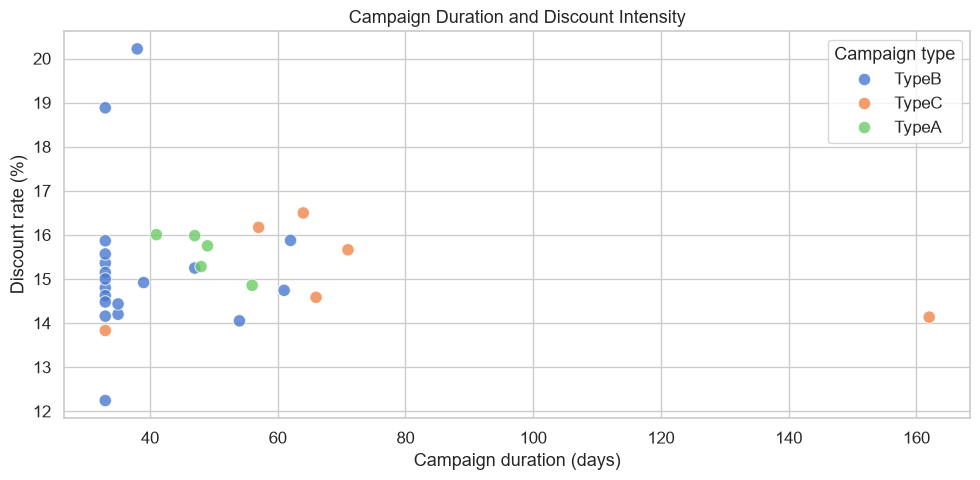

In [55]:
# Visualize campaign duration and discount intensity
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=discount_analysis,
    x="duration_days",
    y="discount_rate",
    hue="campaign_type",
    s=80,
    alpha=0.8
)

plt.title("Campaign Duration and Discount Intensity")
plt.xlabel("Campaign duration (days)")
plt.ylabel("Discount rate (%)")
plt.legend(title="Campaign type")
plt.tight_layout()
plt.show()

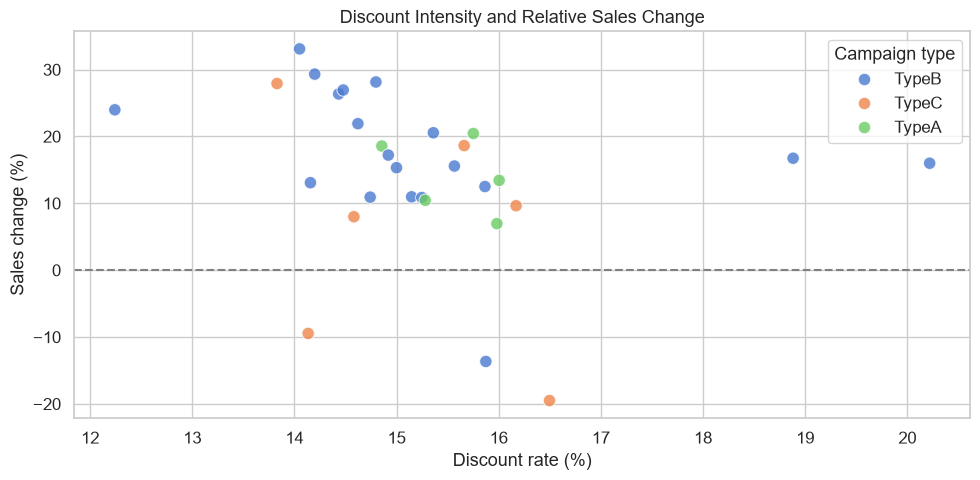

In [56]:
# Visualize discount intensity and relative sales change
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=discount_analysis,
    x="discount_rate",
    y="sales_change_pct",
    hue="campaign_type",
    s=80,
    alpha=0.8
)

plt.axhline(0, color="gray", linestyle="--")
plt.title("Discount Intensity and Relative Sales Change")
plt.xlabel("Discount rate (%)")
plt.ylabel("Sales change (%)")
plt.legend(title="Campaign type")
plt.tight_layout()
plt.show()

In [57]:
# Calculate discount intensity by discount type
discount_analysis["retail_discount_rate"] = (100 * discount_analysis["retail_discount"] / discount_analysis["gross_sales"])
discount_analysis["coupon_discount_rate"] = (100 * discount_analysis["coupon_discount"] / discount_analysis["gross_sales"])
discount_analysis["coupon_match_discount_rate"] = (100 * discount_analysis["coupon_match_discount"] / discount_analysis["gross_sales"])

In [58]:
# Examine correlations by discount type
discount_type_correlation = discount_analysis[
    [
        "duration_days",
        "retail_discount_rate",
        "coupon_discount_rate",
        "coupon_match_discount_rate",
        "mean_sales_change",
        "sales_change_pct"
    ]
].corr(method="spearman")

print(discount_type_correlation.round(3))

                            duration_days  retail_discount_rate  \
duration_days                       1.000                 0.220   
retail_discount_rate                0.220                 1.000   
coupon_discount_rate               -0.303                 0.157   
coupon_match_discount_rate          0.058                 0.467   
mean_sales_change                  -0.574                -0.603   
sales_change_pct                   -0.498                -0.482   

                            coupon_discount_rate  coupon_match_discount_rate  \
duration_days                             -0.303                       0.058   
retail_discount_rate                       0.157                       0.467   
coupon_discount_rate                       1.000                       0.610   
coupon_match_discount_rate                 0.610                       1.000   
mean_sales_change                         -0.112                      -0.335   
sales_change_pct                          -0.068  

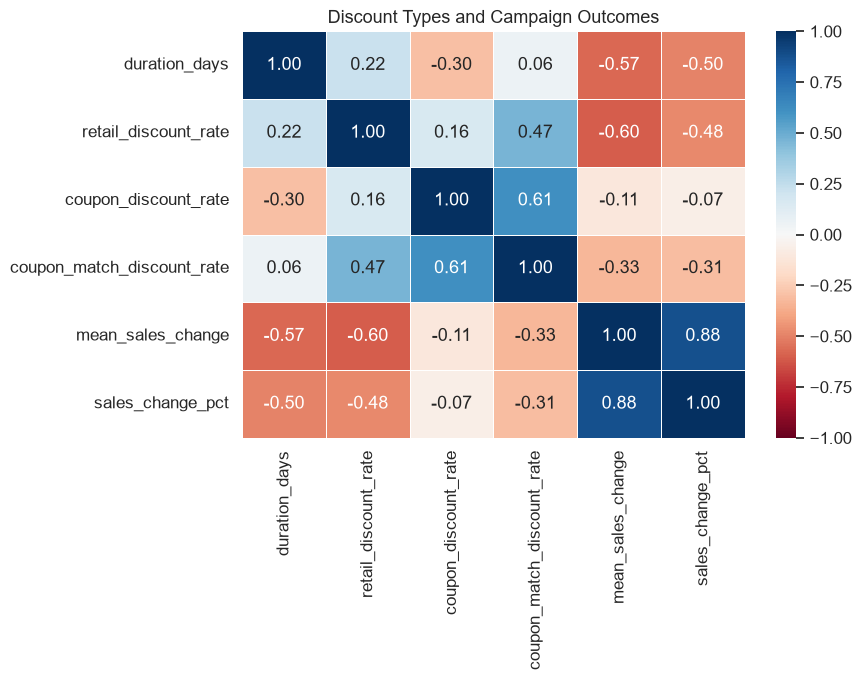

In [59]:
# Visualize correlations between discount types and campaign outcomes
plt.figure(figsize=(9, 7))

sns.heatmap(
    discount_type_correlation,
    annot=True,
    fmt=".2f",
    cmap="RdBu",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Discount Types and Campaign Outcomes")
plt.tight_layout()
plt.show()

In [60]:
# Calculate total discounts by product category
discount_by_category["total_discount"] = (discount_by_category["retail_discount"] + discount_by_category["coupon_discount"] + discount_by_category["coupon_match_discount"])

# Reconstruct gross sales before discounts
discount_by_category["gross_sales"] = (discount_by_category["total_sales"] + discount_by_category["retail_discount"] + discount_by_category["coupon_match_discount"])

# Calculate category-level discount intensity
discount_by_category["discount_rate"] = (100 * discount_by_category["total_discount"] / discount_by_category["gross_sales"].where(discount_by_category["gross_sales"] > 0))

In [61]:
# Combine category sales performance with realized discount intensity
category_discount_analysis = category_performance.merge(
    discount_by_category[
        [
            "campaign",
            "department",
            "commodity_desc",
            "discount_rate"
        ]
    ],
    on=["campaign", "department", "commodity_desc"],
    how="left",
    validate="one_to_one"
)

print(category_discount_analysis.head(10))

   campaign campaign_type  start_day  end_day  duration_days  \
0        26         TypeA        224      264             41   
1        26         TypeA        224      264             41   
2        26         TypeA        224      264             41   
3        26         TypeA        224      264             41   
4        26         TypeA        224      264             41   
5        26         TypeA        224      264             41   
6        26         TypeA        224      264             41   
7        26         TypeA        224      264             41   
8        26         TypeA        224      264             41   
9        26         TypeA        224      264             41   

   assigned_households  before_days  during_days  after_days  \
0                  332          223           41         447   
1                  332          223           41         447   
2                  332          223           41         447   
3                  332          223    

In [62]:
# Calculate discount correlations by product category
category_discount_correlation = (
    category_discount_analysis
    .groupby(["department", "commodity_desc"], dropna=False)[
        ["discount_rate", "duration_days", "sales_change"]
    ]
    .corr(method="spearman")
    .xs("discount_rate", level=-1)
    .reset_index()
    .drop(columns="discount_rate")
    .rename(columns={
        "duration_days": "duration_discount_rho",
        "sales_change": "discount_sales_rho"
    })
)

print(category_discount_correlation.head(15))

         department        commodity_desc  duration_discount_rho  \
0                                                            NaN   
1        AUTOMOTIVE                COUPON                    NaN   
2        AUTOMOTIVE             NEWSPAPER                    NaN   
3   CHARITABLE CONT               UNKNOWN                    NaN   
4       CHEF SHOPPE               UNKNOWN               0.089103   
5   CNTRL/STORE SUP     COUPON/MISC ITEMS                    NaN   
6         COSMETICS                  BATH               0.339613   
7         COSMETICS  COSMETIC ACCESSORIES               0.394711   
8         COSMETICS     COUPON/MISC ITEMS                    NaN   
9         COSMETICS            FRAGRANCES              -0.590805   
10        COSMETICS  MAKEUP AND TREATMENT               0.069506   
11   COUP/STR & MFG   COUPONS/STORE & MFG               0.180339   
12       DAIRY DELI                  EGGS               1.000000   
13       DAIRY DELI      MILK BY-PRODUCTS       

In [63]:
# Count campaigns with available discount rates
category_discount_counts = (
    category_discount_analysis
    .groupby(["department", "commodity_desc"], dropna=False)
    .agg(
        valid_campaigns=("discount_rate", "count")
    )
    .reset_index()
)

category_discount_correlation = category_discount_correlation.merge(
    category_discount_counts,
    on=["department", "commodity_desc"],
    validate="one_to_one"
)

In [64]:
# Select baseline categories for visualization
category_discount_top = category_discount_correlation.merge(
    top_categories,
    on=["department", "commodity_desc"],
    how="inner",
    validate="one_to_one"
)

category_discount_top["category"] = (
    category_discount_top["department"]
    + " / "
    + category_discount_top["commodity_desc"]
)

print(category_discount_top.round(3))

         department          commodity_desc  duration_discount_rho  \
0              DELI              DELI MEATS                 -0.280   
1           DRUG GM              CIGARETTES                 -0.406   
2           GROCERY              BAG SNACKS                  0.094   
3           GROCERY  BAKED BREAD/BUNS/ROLLS                 -0.114   
4           GROCERY              BEERS/ALES                 -0.025   
5           GROCERY                  CHEESE                 -0.101   
6           GROCERY             COLD CEREAL                  0.227   
7           GROCERY     FLUID MILK PRODUCTS                 -0.033   
8           GROCERY            FROZEN PIZZA                 -0.175   
9           GROCERY  FRZN MEAT/MEAT DINNERS                 -0.086   
10          GROCERY             SOFT DRINKS                  0.085   
11        KIOSK-GAS       COUPON/MISC ITEMS                  0.177   
12             MEAT                    BEEF                  0.006   
13             MEAT 

In [65]:
# Prepare category discount correlations for visualization
discount_heatmap = (
    category_discount_top
    .set_index("category")[
        ["duration_discount_rho", "discount_sales_rho"]
    ]
    .rename(columns={
        "duration_discount_rho": "Duration vs. Discount",
        "discount_sales_rho": "Discount vs. Sales Change"
    })
)

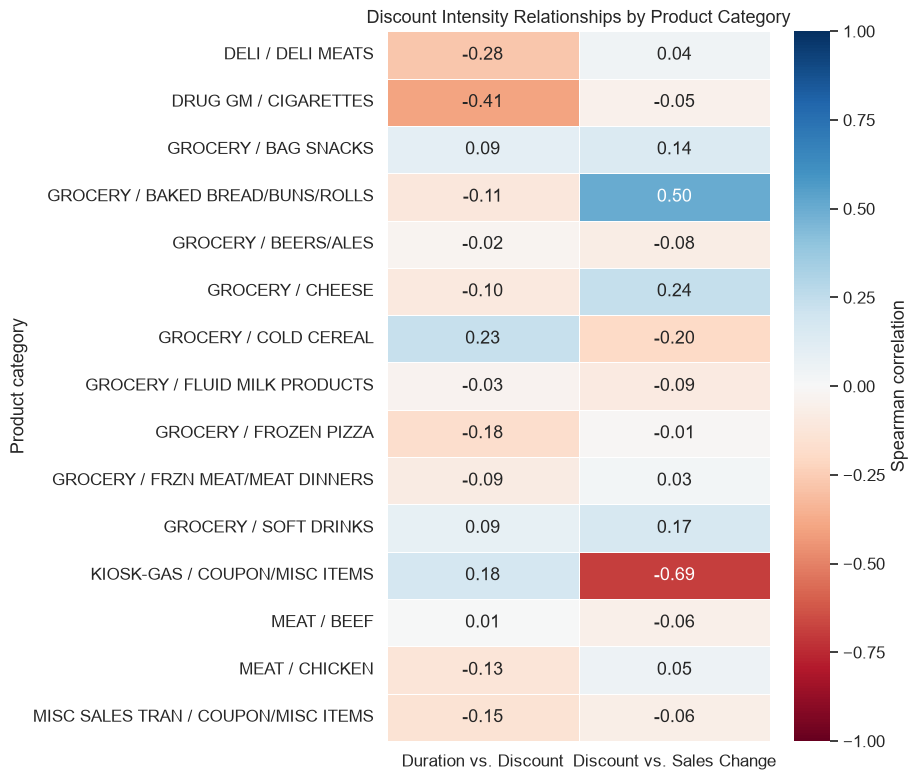

In [66]:
# Visualize discount correlations across product categories
plt.figure(figsize=(9, 8))

sns.heatmap(
    discount_heatmap,
    annot=True,
    fmt=".2f",
    cmap="RdBu",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Spearman correlation"}
)

plt.title("Discount Intensity Relationships by Product Category")
plt.xlabel("")
plt.ylabel("Product category")
plt.tight_layout()
plt.show()

In [67]:
# Exclude selected miscellaneous categories for sensitivity analysis
category_sensitivity = category_performance.loc[
    ~(
        category_performance["department"].isin(
            ["KIOSK-GAS", "MISC SALES TRAN"]
        )
        & (category_performance["commodity_desc"] == "COUPON/MISC ITEMS")
    )
]

# Recalculate campaign-level weekly sales
sales_sensitivity = (
    category_sensitivity
    .groupby("campaign", as_index=False)
    .agg(
        weekly_sales_before=("weekly_sales_before", "sum"),
        weekly_sales_during=("weekly_sales_during", "sum"),
        mean_sales_change=("sales_change", "sum")
    )
)

sales_sensitivity["sales_change_pct"] = (100 * sales_sensitivity["mean_sales_change"] / sales_sensitivity["weekly_sales_before"])

In [68]:
# Exclude the same categories from discount calculations
discount_sensitivity = discount_by_category.loc[
    ~(
        discount_by_category["department"].isin(
            ["KIOSK-GAS", "MISC SALES TRAN"]
        )
        & (discount_by_category["commodity_desc"] == "COUPON/MISC ITEMS")
    )
]

# Recalculate campaign-level discount intensity
discount_sensitivity = (
    discount_sensitivity
    .groupby("campaign", as_index=False)
    .agg(
        total_discount=("total_discount", "sum"),
        gross_sales=("gross_sales", "sum")
    )
)

discount_sensitivity["discount_rate"] = (
    100 * discount_sensitivity["total_discount"]
    / discount_sensitivity["gross_sales"].where(
        discount_sensitivity["gross_sales"] > 0
    )
)

In [69]:
# Combine recalculated sales and discount indicators
sensitivity_analysis = sales_sensitivity.merge(
    discount_sensitivity,
    on="campaign",
    validate="one_to_one"
)

# Compare correlations across analytical variants
discount_sensitivity_results = pd.DataFrame({
    "All categories": discount_analysis[
        ["discount_rate", "mean_sales_change", "sales_change_pct"]
    ].corr(method="spearman")["discount_rate"],

    "Excluding selected miscellaneous categories": sensitivity_analysis[
        ["discount_rate", "mean_sales_change", "sales_change_pct"]
    ].corr(method="spearman")["discount_rate"]
})

print(discount_sensitivity_results.round(3))

                   All categories  Excluding selected miscellaneous categories
discount_rate               1.000                                        1.000
mean_sales_change          -0.584                                       -0.542
sales_change_pct           -0.475                                       -0.391


## 2.10 Temporal Dynamics

In [70]:
# Aggregate daily sales of households assigned to each campaign
campaign_daily_sales = read_query("""
    SELECT
        a.campaign,
        s.day,
        SUM(s.sales_value) AS assigned_sales
    FROM analytics.fact_campaign_assignment AS a
    JOIN analytics.fact_sales AS s
        ON a.household_key = s.household_key
    GROUP BY
        a.campaign,
        s.day
    ORDER BY
        a.campaign,
        s.day;
""")

print(campaign_daily_sales.head(10))

   campaign  day  assigned_sales
0         1    3          351.27
1         1    4          101.31
2         1    5           14.51
3         1    6           51.35
4         1    7          137.28
5         1    8          150.95
6         1   11          118.84
7         1   12           12.31
8         1   14          136.34
9         1   15           51.99


In [71]:
# Aggregate daily sales across all households
daily_sales = read_query("""
    SELECT
        d.day,
        COALESCE(SUM(s.sales_value), 0) AS total_sales
    FROM analytics.dim_day AS d
    LEFT JOIN analytics.fact_sales AS s
        ON d.day = s.day
    WHERE d.week_no IS NOT NULL
    GROUP BY d.day
    ORDER BY d.day;
""")

print(daily_sales.head(10))

   day  total_sales
0    1       549.31
1    2       458.91
2    3      1560.37
3    4      1785.64
4    5       856.93
5    6      1008.15
6    7      1271.29
7    8      1203.85
8    9      1050.95
9   10      1714.38


In [72]:
# Create all campaign-day combinations
campaign_daily = campaign_overview.merge(
    daily_sales,
    how="cross"
)

# Add daily sales of assigned households
campaign_daily = campaign_daily.merge(
    campaign_daily_sales,
    on=["campaign", "day"],
    how="left",
    validate="one_to_one"
)

campaign_daily["assigned_sales"] = (campaign_daily["assigned_sales"].fillna(0))

# Calculate sales of non-assigned households
campaign_daily["non_assigned_sales"] = (campaign_daily["total_sales"] - campaign_daily["assigned_sales"])

campaign_daily["non_assigned_households"] = (2500 - campaign_daily["assigned_households"])

print("Rows:", len(campaign_daily))

Rows: 21330


In [73]:
# Classify days relative to campaign boundaries
campaign_daily["period"] = "During"

campaign_daily.loc[
    campaign_daily["day"] < campaign_daily["start_day"],
    "period"
] = "Before"

campaign_daily.loc[
    campaign_daily["day"] > campaign_daily["end_day"],
    "period"
] = "After"

# Calculate the relative week from campaign start
campaign_daily["relative_week"] = ((campaign_daily["day"] - campaign_daily["start_day"]) // 7)

print(campaign_daily.head(10))

   campaign campaign_type  start_day  end_day  duration_days  \
0        26         TypeA        224      264             41   
1        26         TypeA        224      264             41   
2        26         TypeA        224      264             41   
3        26         TypeA        224      264             41   
4        26         TypeA        224      264             41   
5        26         TypeA        224      264             41   
6        26         TypeA        224      264             41   
7        26         TypeA        224      264             41   
8        26         TypeA        224      264             41   
9        26         TypeA        224      264             41   

   assigned_households  before_days  during_days  after_days  \
0                  332          223           41         447   
1                  332          223           41         447   
2                  332          223           41         447   
3                  332          223    

In [74]:
# Aggregate sales by campaign phase and relative week
campaign_weekly = (
    campaign_daily
    .groupby(
        ["campaign", "campaign_type", "period", "relative_week"],
        as_index=False
    )
    .agg(
        observed_days=("day", "nunique"),
        assigned_sales=("assigned_sales", "sum"),
        non_assigned_sales=("non_assigned_sales", "sum"),
        assigned_households=("assigned_households", "first"),
        non_assigned_households=("non_assigned_households", "first")
    )
)

# Calculate standardized weekly sales per household
campaign_weekly["weekly_assigned_sales"] = (
    campaign_weekly["assigned_sales"]
    / campaign_weekly["assigned_households"]
    / campaign_weekly["observed_days"] * 7
)

campaign_weekly["weekly_non_assigned_sales"] = (
    campaign_weekly["non_assigned_sales"]
    / campaign_weekly["non_assigned_households"]
    / campaign_weekly["observed_days"] * 7
)

print(campaign_weekly.head(15))

    campaign campaign_type period  relative_week  observed_days  \
0          1         TypeB  After              5              4   
1          1         TypeB  After              6              7   
2          1         TypeB  After              7              7   
3          1         TypeB  After              8              7   
4          1         TypeB  After              9              7   
5          1         TypeB  After             10              7   
6          1         TypeB  After             11              7   
7          1         TypeB  After             12              7   
8          1         TypeB  After             13              7   
9          1         TypeB  After             14              7   
10         1         TypeB  After             15              7   
11         1         TypeB  After             16              7   
12         1         TypeB  After             17              7   
13         1         TypeB  After             18              

In [75]:
# Validate observation coverage for each campaign
print(
    campaign_weekly
    .groupby("campaign")["observed_days"]
    .sum()
    .describe()
)

count     30.0
mean     711.0
std        0.0
min      711.0
25%      711.0
50%      711.0
75%      711.0
max      711.0
Name: observed_days, dtype: float64


In [76]:
# Align post-campaign weeks to the campaign end
campaign_daily.loc[
    campaign_daily["period"] == "After",
    "relative_week"
] = (
    campaign_daily["day"]
    - campaign_daily["end_day"] - 1
) // 7

In [77]:
# Summarize weekly purchasing activity by campaign type and phase
temporal_summary = (
    campaign_weekly
    .groupby(
        ["campaign_type", "period", "relative_week"],
        as_index=False
    )
    .agg(
        assigned_sales=("weekly_assigned_sales", "mean"),
        non_assigned_sales=("weekly_non_assigned_sales", "mean"),
        campaigns=("campaign", "nunique")
    )
)

# Calculate the sales gap between household groups
temporal_summary["sales_gap"] = (temporal_summary["assigned_sales"] - temporal_summary["non_assigned_sales"])

print(temporal_summary.head(10))

  campaign_type period  relative_week  assigned_sales  non_assigned_sales  \
0         TypeA  After              5       39.467349           25.773561   
1         TypeA  After              6       50.541466           26.636195   
2         TypeA  After              7       55.413128           26.109485   
3         TypeA  After              8       53.251368           24.615309   
4         TypeA  After              9       55.541323           25.691985   
5         TypeA  After             10       51.909874           23.772195   
6         TypeA  After             11       52.211457           24.000190   
7         TypeA  After             12       56.037309           25.737910   
8         TypeA  After             13       54.981086           26.391376   
9         TypeA  After             14       56.425978           25.979268   

   campaigns  sales_gap  
0          1  13.693789  
1          3  23.905271  
2          4  29.303644  
3          5  28.636058  
4          5  29.84933

In [78]:
# Reshape weekly sales for visualization
temporal_plot = temporal_summary.melt(
    id_vars=["campaign_type", "period", "relative_week"],
    value_vars=["assigned_sales", "non_assigned_sales"],
    var_name="household_group",
    value_name="weekly_sales"
)

# Rename household groups
temporal_plot["household_group"] = (
    temporal_plot["household_group"].replace({
        "assigned_sales": "Assigned households",
        "non_assigned_sales": "Non-assigned households"
    })
)

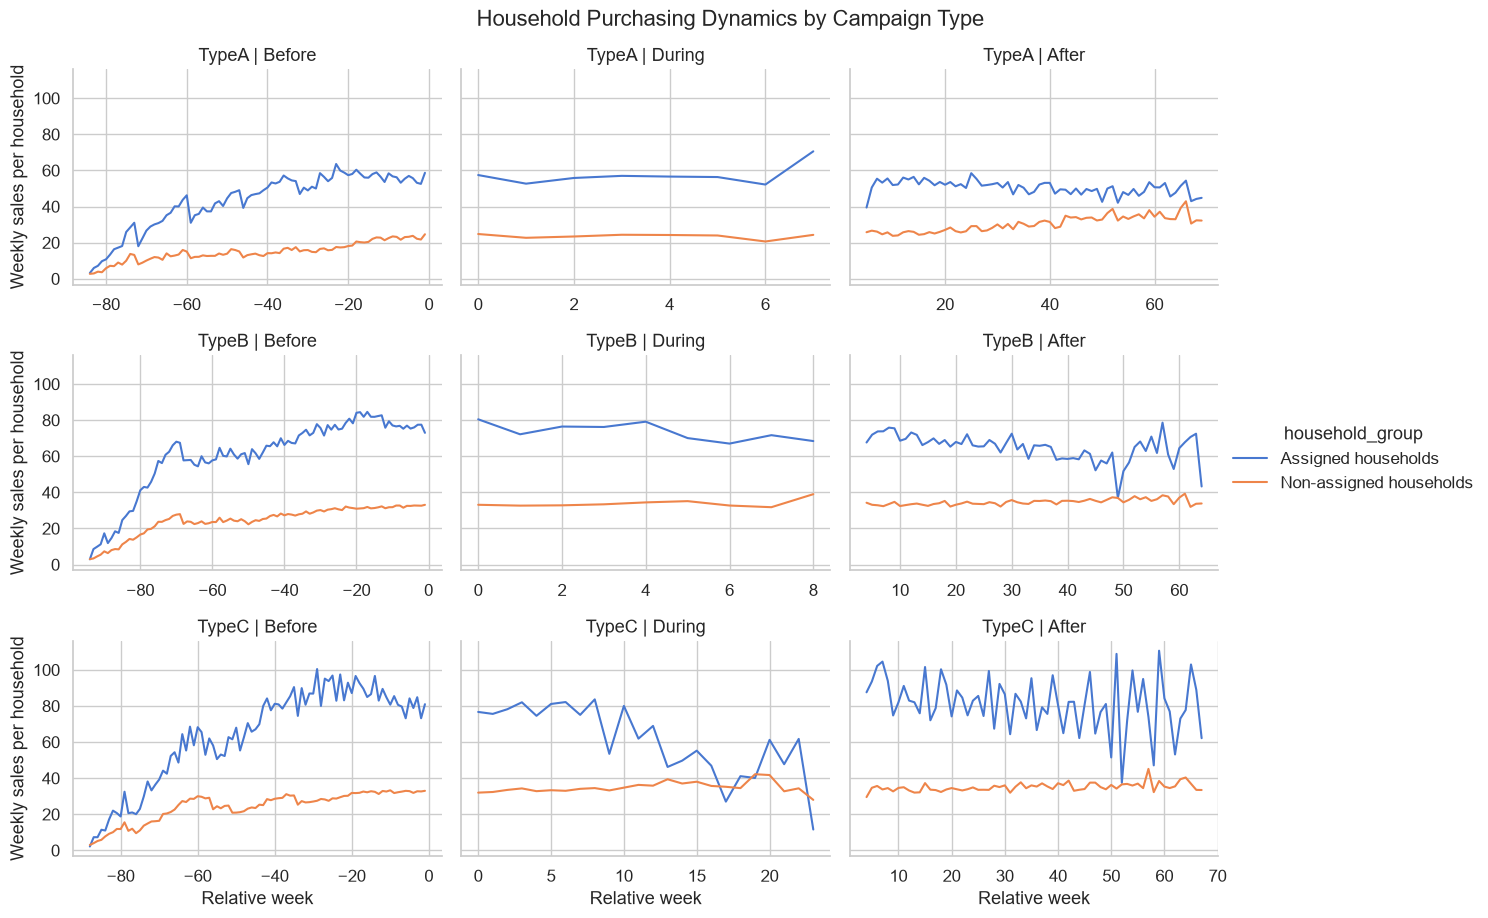

In [79]:
# Visualize purchasing dynamics by campaign type and phase
g = sns.relplot(
    data=temporal_plot,
    x="relative_week",
    y="weekly_sales",
    hue="household_group",
    row="campaign_type",
    col="period",
    row_order=["TypeA", "TypeB", "TypeC"],
    col_order=["Before", "During", "After"],
    kind="line",
    errorbar=None,
    height=3,
    aspect=1.4,
    facet_kws={"sharex": False}
)

g.set_axis_labels(
    "Relative week",
    "Weekly sales per household"
)

g.set_titles("{row_name} | {col_name}")

g.figure.suptitle(
    "Household Purchasing Dynamics by Campaign Type",
    y=1.02
)

plt.show()

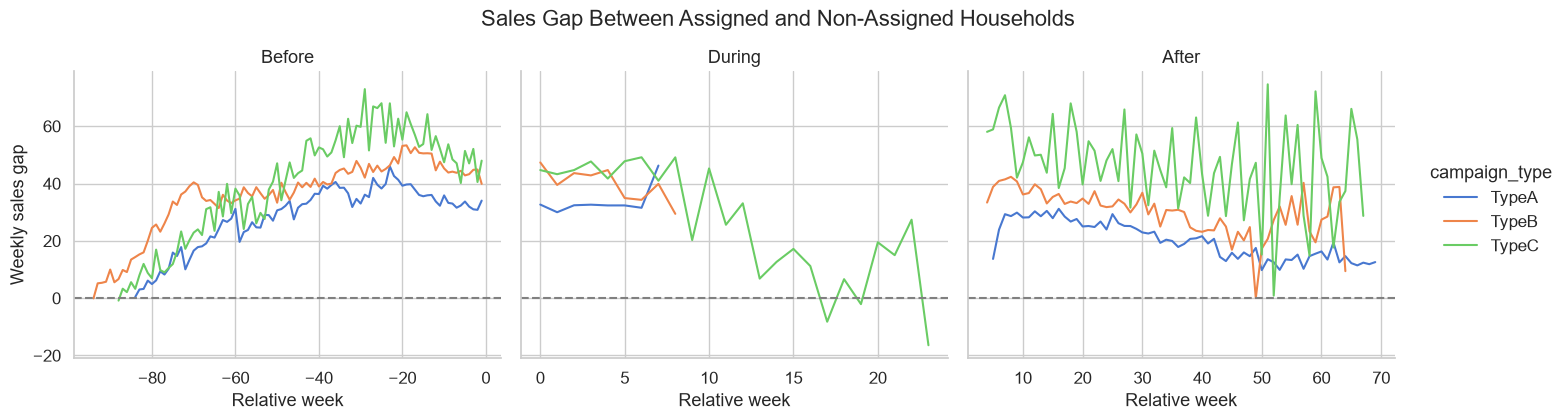

In [80]:
# Visualize the weekly sales gap between household groups
g = sns.relplot(
    data=temporal_summary,
    x="relative_week",
    y="sales_gap",
    hue="campaign_type",
    hue_order=["TypeA", "TypeB", "TypeC"],
    col="period",
    col_order=["Before", "During", "After"],
    kind="line",
    errorbar=None,
    height=4,
    aspect=1.2,
    facet_kws={"sharex": False}
)

g.refline(y=0, color="gray", linestyle="--")
g.set_axis_labels("Relative week", "Weekly sales gap")
g.set_titles("{col_name}")

g.figure.suptitle(
    "Sales Gap Between Assigned and Non-Assigned Households",
    y=1.05
)

plt.show()

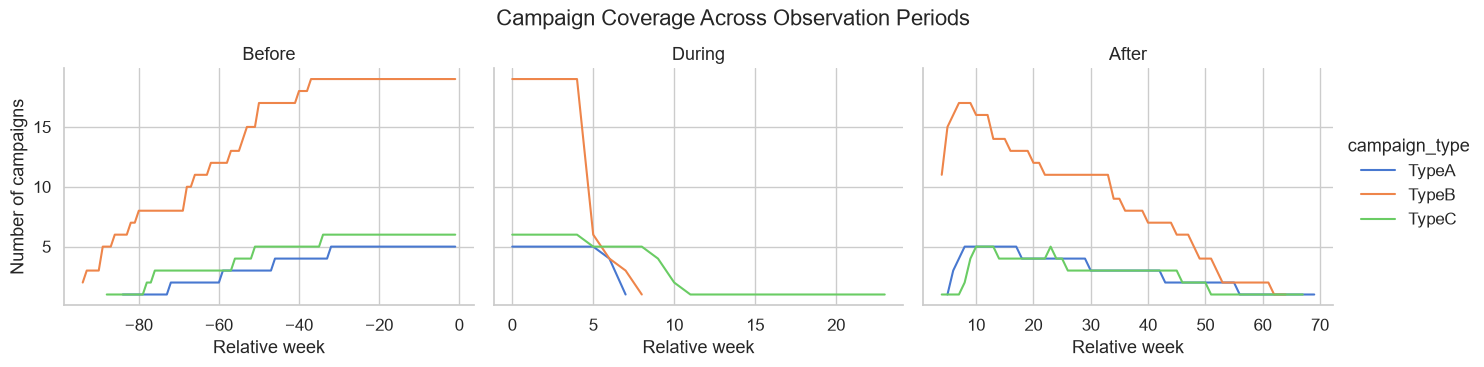

In [81]:
# Visualize campaign coverage across relative weeks
g = sns.relplot(
    data=temporal_summary,
    x="relative_week",
    y="campaigns",
    hue="campaign_type",
    hue_order=["TypeA", "TypeB", "TypeC"],
    col="period",
    col_order=["Before", "During", "After"],
    kind="line",
    errorbar=None,
    height=3.5,
    aspect=1.3,
    facet_kws={"sharex": False}
)

g.set_axis_labels("Relative week", "Number of campaigns")
g.set_titles("{col_name}")

g.figure.suptitle(
    "Campaign Coverage Across Observation Periods",
    y=1.05
)

plt.show()

In [82]:
# Identify the start of the alternative baseline period
stable_period = read_query("""
    SELECT MIN(day) AS first_day
    FROM analytics.dim_day
    WHERE week_no = 19;
""")

stable_start = int(stable_period.loc[0, "first_day"])

print("Alternative baseline start:", stable_start)

Alternative baseline start: 125


In [83]:
# Calculate daily sales gap per household
campaign_daily["daily_sales_gap"] = (
    campaign_daily["assigned_sales"]
    / campaign_daily["assigned_households"]
    - campaign_daily["non_assigned_sales"]
    / campaign_daily["non_assigned_households"]
)

# Calculate the sales gap using the full baseline
full_baseline = (
    campaign_daily.loc[campaign_daily["period"] == "Before"]
    .groupby(["campaign", "campaign_type"])["daily_sales_gap"]
    .mean() * 7
)

# Calculate the sales gap using the alternative baseline
alternative_baseline = (
    campaign_daily.loc[
        (campaign_daily["period"] == "Before")
        & (campaign_daily["day"] >= stable_start)
    ]
    .groupby(["campaign", "campaign_type"])["daily_sales_gap"]
    .mean() * 7
)

# Calculate the sales gap during campaigns
during_gap = (
    campaign_daily.loc[campaign_daily["period"] == "During"]
    .groupby(["campaign", "campaign_type"])["daily_sales_gap"]
    .mean() * 7
)

In [84]:
# Compare changes under alternative baseline definitions
baseline_sensitivity = pd.DataFrame({
    "full_baseline": full_baseline,
    "alternative_baseline": alternative_baseline,
    "during_gap": during_gap
}).reset_index()

baseline_sensitivity["change_full_baseline"] = (
    baseline_sensitivity["during_gap"]
    - baseline_sensitivity["full_baseline"]
)

baseline_sensitivity["change_alternative_baseline"] = (
    baseline_sensitivity["during_gap"]
    - baseline_sensitivity["alternative_baseline"]
)

display(baseline_sensitivity.round(2))

,campaign,campaign_type,full_baseline,alternative_baseline,during_gap,change_full_baseline,change_alternative_baseline
0,1,TypeB,18.36,17.08,18.48,0.12,1.40
1,2,TypeB,16.50,17.02,17.00,0.50,-0.02
2,3,TypeC,52.30,50.11,53.06,0.76,2.94
3,4,TypeB,26.99,36.00,36.17,9.18,0.17
4,5,TypeB,41.59,51.99,55.20,13.61,3.22
5,6,TypeC,53.55,68.20,69.06,15.52,0.87
6,7,TypeB,33.24,41.51,42.03,8.79,0.52
7,8,TypeA,31.30,39.07,36.47,5.16,-2.60
8,9,TypeB,19.96,24.25,23.93,3.97,-0.32
9,10,TypeB,41.75,50.49,43.10,1.34,-7.39


In [85]:
# Summarize baseline sensitivity by campaign type
baseline_by_type = (
    baseline_sensitivity
    .groupby("campaign_type")[
        [
            "change_full_baseline",
            "change_alternative_baseline"
        ]
    ]
    .mean()
)

display(baseline_by_type.round(2))

,change_full_baseline,change_alternative_baseline
campaign_type,,
TypeA,0.53,-2.22
TypeB,4.70,-1.18
TypeC,-2.13,-4.62


In [86]:
# Prepare baseline comparison for visualization
baseline_plot = baseline_by_type.reset_index().melt(
    id_vars="campaign_type",
    var_name="baseline",
    value_name="sales_gap_change"
)

baseline_plot["baseline"] = baseline_plot["baseline"].replace({
    "change_full_baseline": "Full baseline",
    "change_alternative_baseline": "Baseline from week 19"
})

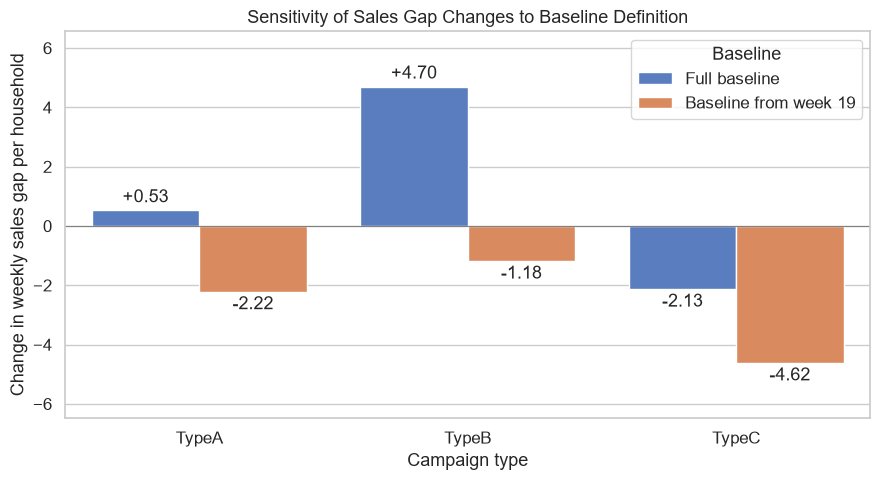

In [87]:
# Visualize sensitivity to baseline definition
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=baseline_plot,
    x="campaign_type",
    y="sales_gap_change",
    hue="baseline",
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(container, fmt="%+.2f", padding=3)

plt.axhline(0, color="gray", linewidth=0.8)
plt.title("Sensitivity of Sales Gap Changes to Baseline Definition")
plt.xlabel("Campaign type")
plt.ylabel("Change in weekly sales gap per household")
plt.legend(title="Baseline")
plt.margins(y=0.2)
plt.tight_layout()
plt.show()

In [88]:
# Calculate sales gaps using alternative baseline windows
baseline_12w = (
    campaign_daily.loc[
        (campaign_daily["period"] == "Before")
        & (campaign_daily["day"] >= campaign_daily["start_day"] - 84)
    ]
    .groupby(["campaign", "campaign_type"])["daily_sales_gap"]
    .mean() * 7
)

baseline_8w = (
    campaign_daily.loc[
        (campaign_daily["period"] == "Before")
        & (campaign_daily["day"] >= campaign_daily["start_day"] - 56)
    ]
    .groupby(["campaign", "campaign_type"])["daily_sales_gap"]
    .mean() * 7
)

baseline_4w = (
    campaign_daily.loc[
        (campaign_daily["period"] == "Before")
        & (campaign_daily["day"] >= campaign_daily["start_day"] - 28)
    ]
    .groupby(["campaign", "campaign_type"])["daily_sales_gap"]
    .mean() * 7
)

In [89]:
# Compare sales gap changes across baseline definitions
baseline_comparison = pd.DataFrame({
    "Full baseline": during_gap - full_baseline,
    "From week 19": during_gap - alternative_baseline,
    "12 weeks": during_gap - baseline_12w,
    "8 weeks": during_gap - baseline_8w,
    "4 weeks": during_gap - baseline_4w
}).reset_index()

# Summarize results using equal campaign weights
baseline_comparison_by_type = (
    baseline_comparison
    .groupby("campaign_type")
    .mean(numeric_only=True)
    .drop(columns="campaign")
)

display(baseline_comparison_by_type.round(2))

,Full baseline,From week 19,12 weeks,8 weeks,4 weeks
campaign_type,,,,,
TypeA,0.53,-2.22,-0.78,-0.29,0.06
TypeB,4.70,-1.18,-0.99,-0.38,-0.09
TypeC,-2.13,-4.62,-1.87,0.00,-0.07


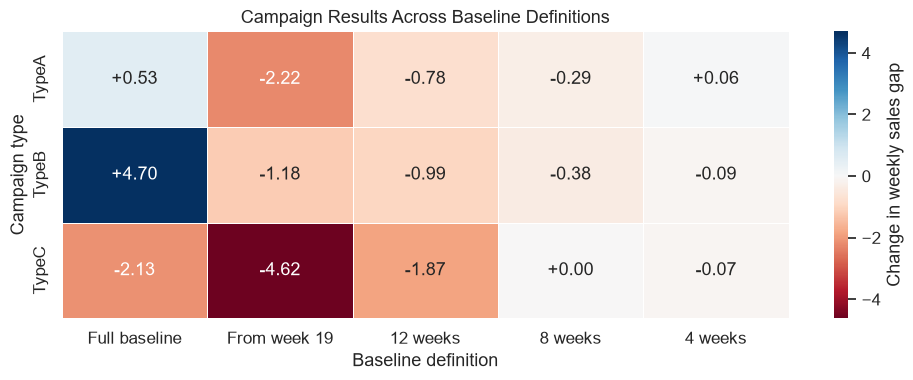

In [90]:
# Visualize sensitivity across baseline definitions
plt.figure(figsize=(10, 4))

sns.heatmap(
    baseline_comparison_by_type,
    annot=True,
    fmt="+.2f",
    cmap="RdBu",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Change in weekly sales gap"}
)

plt.title("Campaign Results Across Baseline Definitions")
plt.xlabel("Baseline definition")
plt.ylabel("Campaign type")
plt.tight_layout()
plt.show()

## 2.11 Coupon-Eligible Product Analysis

In [91]:
# Identify coupon-eligible products by campaign and category
campaign_product_scope = read_query("""
    SELECT
        b.campaign,
        p.department,
        p.commodity_desc,
        COUNT(DISTINCT b.product_id) AS eligible_products,
        COUNT(DISTINCT b.coupon_upc) AS coupons
    FROM analytics.bridge_coupon_product AS b
    JOIN analytics.dim_product AS p
        ON b.product_id = p.product_id
    GROUP BY
        b.campaign,
        p.department,
        p.commodity_desc;
""")

print(campaign_product_scope.head(15))

    campaign department             commodity_desc  eligible_products  coupons
0          1    GROCERY              CANNED JUICES                  5        2
1          1    GROCERY                     CHEESE                111        3
2          1    GROCERY          CONDIMENTS/SAUCES                  1        1
3          1    GROCERY       FRUIT - SHELF STABLE                 63        1
4          1    GROCERY     FRZN MEAT/MEAT DINNERS                 44        2
5          1    GROCERY     FRZN NOVELTIES/WTR ICE                  6        1
6          1    GROCERY           MILK BY-PRODUCTS                 21        1
7          1    GROCERY     REFRGRATD JUICES/DRNKS                 19        1
8          1    GROCERY  VEGETABLES - SHELF STABLE                 95        1
9          1    GROCERY                     YOGURT                 18        1
10         2    GROCERY                     CHEESE                  2        1
11         2    GROCERY     DRY BN/VEG/POTATO/RICE  

In [92]:
# Summarize campaign product scope
campaign_scope = (
    campaign_product_scope
    .groupby("campaign", as_index=False)
    .agg(
        eligible_products=("eligible_products", "sum"),
        eligible_categories=("commodity_desc", "size"),
        eligible_departments=("department", "nunique")
    )
)

campaign_scope = campaign_scope.merge(
    campaign_overview[
        ["campaign", "campaign_type", "duration_days"]
    ],
    on="campaign",
    validate="one_to_one"
)

print(campaign_scope.sort_values("eligible_products", ascending=False))

    campaign  eligible_products  eligible_categories  eligible_departments  \
12        13              35616                  268                    28   
17        18              35513                  269                    28   
7          8              17178                  197                    23   
25        26               3396                   85                    10   
29        30               3205                  104                    11   
21        22               1917                   18                     4   
23        24               1887                   11                     4   
15        16               1025                   12                     4   
24        25                826                   20                     5   
8          9                825                   31                     3   
22        23                767                   39                     3   
13        14                714                   17            

In [93]:
# Aggregate daily sales of coupon-eligible products
eligible_daily_sales = read_query("""
    WITH eligible_products AS (
        SELECT DISTINCT campaign, product_id
        FROM analytics.bridge_coupon_product
    )
    SELECT
        e.campaign,
        s.day,
        SUM(s.sales_value) AS eligible_total_sales,
        COALESCE(SUM(s.sales_value) FILTER (WHERE a.household_key IS NOT NULL), 0) AS eligible_assigned_sales
    FROM eligible_products AS e
    JOIN analytics.fact_sales AS s
        ON e.product_id = s.product_id
    LEFT JOIN analytics.fact_campaign_assignment AS a
        ON e.campaign = a.campaign
       AND s.household_key = a.household_key
    GROUP BY
        e.campaign,
        s.day
    ORDER BY
        e.campaign,
        s.day;
""")

print(eligible_daily_sales.head(10))

   campaign  day  eligible_total_sales  eligible_assigned_sales
0         1    1                  5.73                     0.00
1         1    2                  2.09                     0.00
2         1    3                 16.79                     6.05
3         1    4                 11.32                     0.00
4         1    5                  2.19                     0.00
5         1    6                  4.68                     0.00
6         1    7                 15.73                     3.76
7         1    8                  8.34                     0.00
8         1    9                 14.31                     0.00
9         1   10                  7.16                     0.00


In [94]:
# Combine total sales with coupon-eligible product sales
campaign_product_daily = campaign_daily.merge(
    eligible_daily_sales,
    on=["campaign", "day"],
    how="left",
    validate="one_to_one"
)

campaign_product_daily[
    ["eligible_total_sales", "eligible_assigned_sales"]
] = campaign_product_daily[
    ["eligible_total_sales", "eligible_assigned_sales"]
].fillna(0)

In [95]:
# Calculate eligible product sales among non-assigned households
campaign_product_daily["eligible_non_assigned_sales"] = (
    campaign_product_daily["eligible_total_sales"]
    - campaign_product_daily["eligible_assigned_sales"]
)

In [96]:
# Calculate sales of other products
campaign_product_daily["other_assigned_sales"] = (
    campaign_product_daily["assigned_sales"]
    - campaign_product_daily["eligible_assigned_sales"]
)

campaign_product_daily["other_non_assigned_sales"] = (
    campaign_product_daily["non_assigned_sales"]
    - campaign_product_daily["eligible_non_assigned_sales"]
)

print("Rows:", len(campaign_product_daily))

Rows: 21330


In [97]:
# Calculate daily sales gaps by product scope
campaign_product_daily["total_sales_gap"] = (
    campaign_product_daily["assigned_sales"]
    / campaign_product_daily["assigned_households"]
    - campaign_product_daily["non_assigned_sales"]
    / campaign_product_daily["non_assigned_households"]
)

campaign_product_daily["eligible_sales_gap"] = (
    campaign_product_daily["eligible_assigned_sales"]
    / campaign_product_daily["assigned_households"]
    - campaign_product_daily["eligible_non_assigned_sales"]
    / campaign_product_daily["non_assigned_households"]
)

campaign_product_daily["other_sales_gap"] = (
    campaign_product_daily["other_assigned_sales"]
    / campaign_product_daily["assigned_households"]
    - campaign_product_daily["other_non_assigned_sales"]
    / campaign_product_daily["non_assigned_households"]
)

In [98]:
# Reshape sales gaps by product scope
product_gap_long = campaign_product_daily.drop(
    columns="daily_sales_gap"
).melt(
    id_vars=[
        "campaign",
        "campaign_type",
        "day",
        "start_day",
        "period"
    ],
    value_vars=[
        "total_sales_gap",
        "eligible_sales_gap",
        "other_sales_gap"
    ],
    var_name="product_scope",
    value_name="daily_sales_gap"
)

display(product_gap_long.head())

,campaign,campaign_type,day,start_day,period,product_scope,daily_sales_gap
0,26,TypeA,1,224,Before,total_sales_gap,1.488108
1,26,TypeA,2,224,Before,total_sales_gap,0.941184
2,26,TypeA,3,224,Before,total_sales_gap,1.050719
3,26,TypeA,4,224,Before,total_sales_gap,1.803016
4,26,TypeA,5,224,Before,total_sales_gap,0.611161


In [99]:
# Calculate weekly sales gaps by campaign phase and product scope
product_gap_summary = (
    product_gap_long
    .groupby(
        ["campaign", "campaign_type", "product_scope", "period"]
    )["daily_sales_gap"]
    .mean()
    .mul(7)
    .unstack("period")
    .reset_index()
)

# Calculate changes relative to the full baseline
product_gap_summary["change_during"] = (
    product_gap_summary["During"]
    - product_gap_summary["Before"]
)

product_gap_summary["change_after"] = (
    product_gap_summary["After"]
    - product_gap_summary["Before"]
)

display(product_gap_summary.round(3))

period,campaign,campaign_type,product_scope,After,Before,During,change_during,change_after
0,1,TypeB,eligible_sales_gap,0.172,0.293,0.226,-0.067,-0.121
1,1,TypeB,other_sales_gap,14.899,18.064,18.252,0.188,-3.165
2,1,TypeB,total_sales_gap,15.072,18.357,18.478,0.121,-3.286
3,2,TypeB,eligible_sales_gap,0.070,0.213,0.234,0.021,-0.143
4,2,TypeB,other_sales_gap,7.832,16.284,16.765,0.482,-8.452
...,...,...,...,...,...,...,...,...
85,29,TypeB,other_sales_gap,18.165,16.110,21.303,5.192,2.055
86,29,TypeB,total_sales_gap,18.703,16.679,22.200,5.521,2.024
87,30,TypeA,eligible_sales_gap,0.923,1.391,1.343,-0.049,-0.468
88,30,TypeA,other_sales_gap,15.293,24.583,20.217,-4.366,-9.290


In [100]:
# Calculate the baseline from week 19
product_baseline_stable = (
    product_gap_long.loc[
        (product_gap_long["period"] == "Before")
        & (product_gap_long["day"] >= stable_start)
    ]
    .groupby(
        ["campaign", "campaign_type", "product_scope"]
    )["daily_sales_gap"]
    .mean()
    .mul(7)
    .reset_index(name="baseline_week19")
)

# Calculate the four-week baseline
product_baseline_4w = (
    product_gap_long.loc[
        (product_gap_long["period"] == "Before")
        & (product_gap_long["day"] >= product_gap_long["start_day"] - 28)
    ]
    .groupby(
        ["campaign", "campaign_type", "product_scope"]
    )["daily_sales_gap"]
    .mean()
    .mul(7)
    .reset_index(name="baseline_4w")
)

In [101]:
# Add alternative baseline definitions
product_gap_summary = product_gap_summary.merge(
    product_baseline_stable,
    on=["campaign", "campaign_type", "product_scope"],
    validate="one_to_one"
)

product_gap_summary = product_gap_summary.merge(
    product_baseline_4w,
    on=["campaign", "campaign_type", "product_scope"],
    validate="one_to_one"
)

# Calculate changes under alternative baseline definitions
product_gap_summary["change_week19"] = (
    product_gap_summary["During"]
    - product_gap_summary["baseline_week19"]
)

product_gap_summary["change_4w"] = (
    product_gap_summary["During"]
    - product_gap_summary["baseline_4w"]
)

In [102]:
# Summarize sales gap changes by campaign type and product scope
product_gap_by_type = (
    product_gap_summary
    .groupby(["campaign_type", "product_scope"])[
        ["change_during", "change_week19", "change_4w"]
    ]
    .mean()
    .reset_index()
)

print(product_gap_by_type.round(3))

  campaign_type       product_scope  change_during  change_week19  change_4w
0         TypeA  eligible_sales_gap          0.727         -0.809     -0.028
1         TypeA     other_sales_gap         -0.197         -1.407      0.091
2         TypeA     total_sales_gap          0.530         -2.216      0.063
3         TypeB  eligible_sales_gap          0.152          0.020     -0.007
4         TypeB     other_sales_gap          4.550         -1.204     -0.081
5         TypeB     total_sales_gap          4.702         -1.184     -0.088
6         TypeC  eligible_sales_gap         -0.099         -0.081      0.059
7         TypeC     other_sales_gap         -2.030         -4.536     -0.127
8         TypeC     total_sales_gap         -2.128         -4.617     -0.068


In [103]:
# Prepare readable labels for visualization
product_gap_by_type["product_scope"] = (
    product_gap_by_type["product_scope"].replace({
        "total_sales_gap": "Total sales",
        "eligible_sales_gap": "Coupon-eligible products",
        "other_sales_gap": "Other products"
    })
)

# Prepare the product scope comparison matrix
product_gap_heatmap = (
    product_gap_by_type
    .set_index(["campaign_type", "product_scope"])
    .rename(columns={
        "change_during": "Full baseline",
        "change_week19": "From week 19",
        "change_4w": "4 weeks"
    })
)

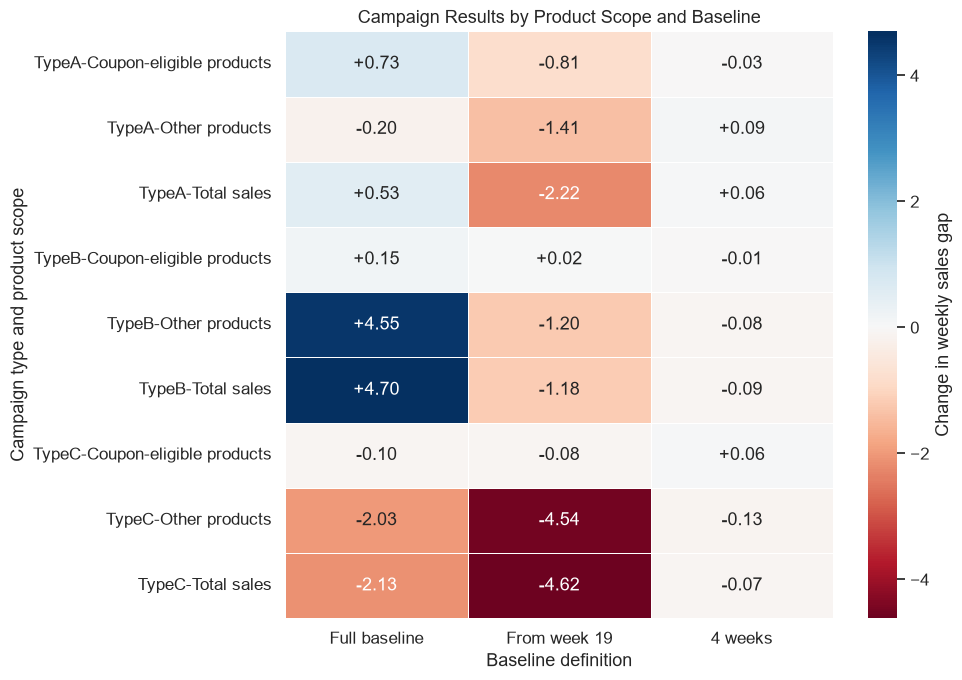

In [104]:
# Visualize sales gap changes by product scope and baseline
plt.figure(figsize=(10, 7))

sns.heatmap(
    product_gap_heatmap,
    annot=True,
    fmt="+.2f",
    cmap="RdBu",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Change in weekly sales gap"}
)

plt.title("Campaign Results by Product Scope and Baseline")
plt.xlabel("Baseline definition")
plt.ylabel("Campaign type and product scope")
plt.tight_layout()
plt.show()

In [105]:
# Calculate sales gap contributions by eligible product category
eligible_category_gaps = read_query("""
    WITH eligible_products AS (
        SELECT DISTINCT campaign, product_id
        FROM analytics.bridge_coupon_product
    ),

    campaign_sizes AS (
        SELECT
            campaign,
            COUNT(*) AS assigned_households
        FROM analytics.fact_campaign_assignment
        GROUP BY campaign
    ),

    sales_contributions AS (
        SELECT
            e.campaign,
            p.department,
            p.commodity_desc,
            s.day,
            d.week_no,
            c.start_day,
            c.end_day,

            CASE
                WHEN a.household_key IS NOT NULL
                THEN s.sales_value / cs.assigned_households
                ELSE -s.sales_value / (2500 - cs.assigned_households)
            END AS sales_gap

        FROM eligible_products AS e

        JOIN analytics.fact_sales AS s
            ON e.product_id = s.product_id

        JOIN analytics.dim_product AS p
            ON s.product_id = p.product_id

        JOIN analytics.dim_campaign AS c
            ON e.campaign = c.campaign

        JOIN campaign_sizes AS cs
            ON e.campaign = cs.campaign

        JOIN analytics.dim_day AS d
            ON s.day = d.day

        LEFT JOIN analytics.fact_campaign_assignment AS a
            ON e.campaign = a.campaign
           AND s.household_key = a.household_key
    )

    SELECT
        campaign,
        department,
        commodity_desc,

        COALESCE(SUM(sales_gap) FILTER (
            WHERE day < start_day
        ), 0) AS gap_before,

        COALESCE(SUM(sales_gap) FILTER (
            WHERE day < start_day AND week_no >= 19
        ), 0) AS gap_week19,

        COALESCE(SUM(sales_gap) FILTER (
            WHERE day BETWEEN start_day - 28 AND start_day - 1
        ), 0) AS gap_4w,

        COALESCE(SUM(sales_gap) FILTER (
            WHERE day BETWEEN start_day AND end_day
        ), 0) AS gap_during,

        COALESCE(SUM(sales_gap) FILTER (
            WHERE day > end_day
        ), 0) AS gap_after

    FROM sales_contributions

    GROUP BY
        campaign,
        department,
        commodity_desc;
""")

display(eligible_category_gaps.head(10))

,campaign,department,commodity_desc,gap_before,gap_week19,gap_4w,gap_during,gap_after
0,1,GROCERY,CANNED JUICES,0.171391,0.177982,-0.010414,-0.030635,0.517562
1,1,GROCERY,CHEESE,1.512138,0.126602,-0.031943,-0.273764,1.257920
2,1,GROCERY,CONDIMENTS/SAUCES,-0.012413,-0.010454,-0.001021,0.000000,0.000000
3,1,GROCERY,FRUIT - SHELF STABLE,2.781888,2.719061,1.201864,-0.026092,1.041038
4,1,GROCERY,FRZN MEAT/MEAT DINNERS,3.104079,2.983390,1.064707,0.973996,3.714856
5,1,GROCERY,FRZN NOVELTIES/WTR ICE,-0.112163,-0.082819,-0.012831,-0.027274,-0.160229
6,1,GROCERY,MILK BY-PRODUCTS,1.286319,0.024940,-0.197459,-0.285271,-0.961466
7,1,GROCERY,REFRGRATD JUICES/DRNKS,2.097261,1.637509,0.150627,0.034465,-0.299650
8,1,GROCERY,VEGETABLES - SHELF STABLE,3.664657,1.971974,0.588665,0.938348,1.130972
9,1,GROCERY,YOGURT,-0.039654,-0.039654,-0.032207,-0.074660,1.839616


In [106]:
# Preserve all eligible campaign-category combinations
eligible_category_analysis = campaign_product_scope.merge(
    eligible_category_gaps,
    on=["campaign", "department", "commodity_desc"],
    how="left",
    validate="one_to_one"
)

# Add campaign characteristics and observation periods
eligible_category_analysis = eligible_category_analysis.merge(
    campaign_overview,
    on="campaign",
    how="left",
    validate="many_to_one"
)

# Fill missing recorded sales gaps with zero
gap_columns = [
    "gap_before",
    "gap_week19",
    "gap_4w",
    "gap_during",
    "gap_after"
]

eligible_category_analysis[gap_columns] = (
    eligible_category_analysis[gap_columns].fillna(0)
)

In [107]:
# Calculate weekly sales gaps for each baseline
eligible_category_analysis["weekly_gap_before"] = (
    eligible_category_analysis["gap_before"]
    / eligible_category_analysis["before_days"] * 7
)

eligible_category_analysis["weekly_gap_week19"] = (
    eligible_category_analysis["gap_week19"]
    / (eligible_category_analysis["start_day"] - stable_start) * 7
)

eligible_category_analysis["weekly_gap_4w"] = (
    eligible_category_analysis["gap_4w"] / 28 * 7
)

# Calculate weekly sales gaps during and after campaigns
eligible_category_analysis["weekly_gap_during"] = (
    eligible_category_analysis["gap_during"]
    / eligible_category_analysis["during_days"] * 7
)

eligible_category_analysis["weekly_gap_after"] = (
    eligible_category_analysis["gap_after"]
    / eligible_category_analysis["after_days"].replace(0, float("nan")) * 7
)

In [108]:
# Calculate sales gap changes across baseline definitions
eligible_category_analysis["change_during"] = (
    eligible_category_analysis["weekly_gap_during"]
    - eligible_category_analysis["weekly_gap_before"]
)

eligible_category_analysis["change_week19"] = (
    eligible_category_analysis["weekly_gap_during"]
    - eligible_category_analysis["weekly_gap_week19"]
)

eligible_category_analysis["change_4w"] = (
    eligible_category_analysis["weekly_gap_during"]
    - eligible_category_analysis["weekly_gap_4w"]
)

eligible_category_analysis["change_after"] = (
    eligible_category_analysis["weekly_gap_after"]
    - eligible_category_analysis["weekly_gap_before"]
)

In [109]:
# Validate category-level changes against campaign-level results
change_columns = [
    "change_during",
    "change_week19",
    "change_4w",
    "change_after"
]

category_totals = (
    eligible_category_analysis
    .groupby("campaign")[change_columns]
    .sum(min_count=1)
)

eligible_totals = (
    product_gap_summary.loc[
        product_gap_summary["product_scope"] == "eligible_sales_gap"
    ]
    .set_index("campaign")[change_columns]
)

print(
    (category_totals - eligible_totals)
    .abs()
    .max()
    .round(6)
)

change_during    0.0
change_week19    0.0
change_4w        0.0
change_after     0.0
dtype: float64


In [110]:
# Summarize eligible category performance by campaign type
eligible_category_by_type = (
    eligible_category_analysis
    .groupby(
        ["campaign_type", "department", "commodity_desc"],
        as_index=False
    )
    .agg(
        campaigns=("campaign", "nunique"),
        change_full=("change_during", "mean"),
        change_week19=("change_week19", "mean"),
        change_4w=("change_4w", "mean")
    )
)

print(
    eligible_category_by_type
    .sort_values("campaigns", ascending=False)
    .round(3)
    .head(30)
)

    campaign_type  department                  commodity_desc  campaigns  \
357         TypeB     GROCERY                    FROZEN PIZZA         11   
339         TypeB     GROCERY                          CHEESE         11   
360         TypeB     GROCERY          FRZN MEAT/MEAT DINNERS         10   
381         TypeB     GROCERY          REFRGRATD JUICES/DRNKS          8   
354         TypeB     GROCERY              FROZEN BREAD/DOUGH          6   
345         TypeB     GROCERY            CRACKERS/MISC BKD FD          6   
380         TypeB     GROCERY        REFRGRATD DOUGH PRODUCTS          5   
209         TypeA  MEAT-PCKGD                     FROZEN MEAT          5   
210         TypeA  MEAT-PCKGD                      HEAT/SERVE          5   
125         TypeA     GROCERY  CONVENIENT BRKFST/WHLSM SNACKS          5   
142         TypeA     GROCERY             FROZEN PIE/DESSERTS          5   
149         TypeA     GROCERY          FRZN MEAT/MEAT DINNERS          5   
143         

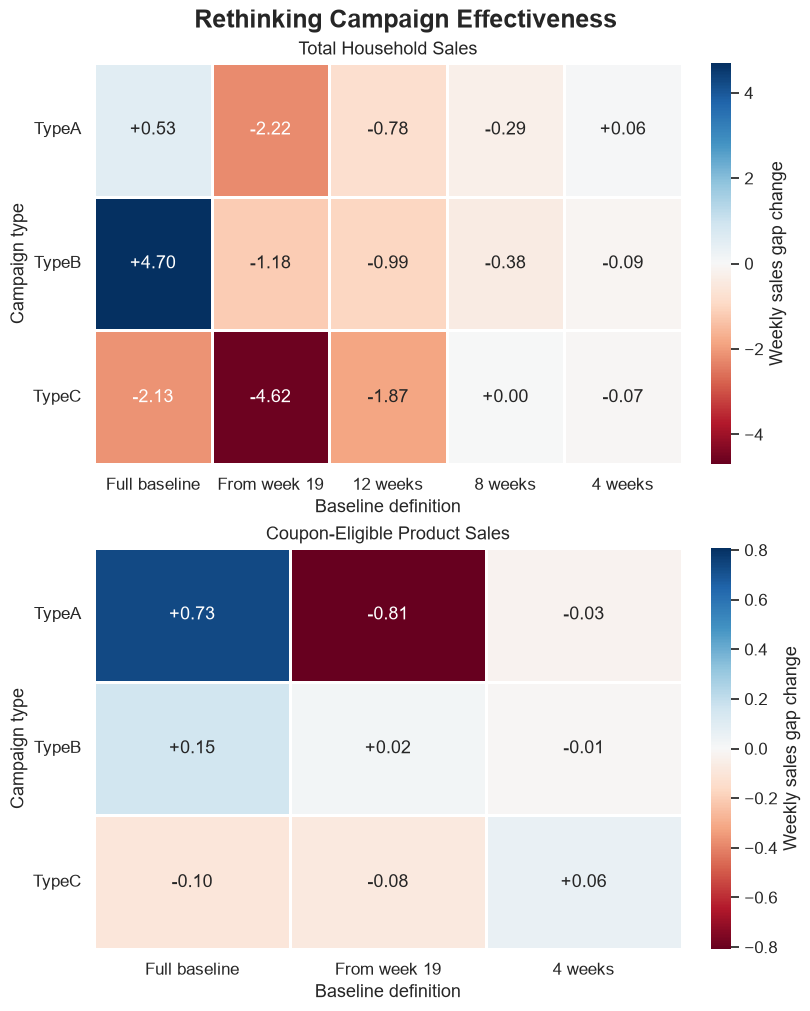

In [111]:
# Prepare eligible product sales changes
eligible_baseline_comparison = (
    product_gap_summary.loc[
        product_gap_summary["product_scope"] == "eligible_sales_gap"
    ]
    .groupby("campaign_type")[
        ["change_during", "change_week19", "change_4w"]
    ]
    .mean()
    .rename(columns={
        "change_during": "Full baseline",
        "change_week19": "From week 19",
        "change_4w": "4 weeks"
    })
)

# Set symmetric color scales
total_limit = baseline_comparison_by_type.abs().max().max()
eligible_limit = eligible_baseline_comparison.abs().max().max()

# Combine baseline sensitivity and eligible product results
fig, axes = plt.subplots(
    2, 1,
    figsize=(8, 10),
    layout="constrained"
)

sns.heatmap(
    baseline_comparison_by_type,
    annot=True,
    fmt="+.2f",
    cmap="RdBu",
    center=0,
    vmin=-total_limit,
    vmax=total_limit,
    linewidths=1,
    cbar_kws={"label": "Weekly sales gap change"},
    ax=axes[0]
)

axes[0].set_title("Total Household Sales")
axes[0].set_xlabel("Baseline definition")
axes[0].set_ylabel("Campaign type")
axes[0].tick_params(axis="x", rotation=0)
axes[0].tick_params(axis="y", rotation=0)

# Visualize coupon-eligible product sales
sns.heatmap(
    eligible_baseline_comparison,
    annot=True,
    fmt="+.2f",
    cmap="RdBu",
    center=0,
    vmin=-eligible_limit,
    vmax=eligible_limit,
    linewidths=1,
    cbar_kws={"label": "Weekly sales gap change"},
    ax=axes[1]
)

axes[1].set_title("Coupon-Eligible Product Sales")
axes[1].set_xlabel("Baseline definition")
axes[1].set_ylabel("Campaign type")
axes[1].tick_params(axis="x", rotation=0)
axes[1].tick_params(axis="y", rotation=0)

fig.suptitle(
    "Rethinking Campaign Effectiveness",
    fontsize=18,
    fontweight="bold"
)

plt.show()

## 2.12 Coupon Redemption Analysis

In [112]:
# Count unique coupons in each campaign
campaign_coupon_counts = read_query("""
    SELECT
        campaign,
        COUNT(*) AS coupon_pool_size
    FROM analytics.dim_coupon
    GROUP BY campaign
    ORDER BY campaign;
""")

display(campaign_coupon_counts)

,campaign,coupon_pool_size
0,1,11
1,2,16
2,3,34
3,4,12
4,5,11
5,6,1
6,7,8
7,8,209
8,9,18
9,10,14


In [113]:
# Aggregate coupon redemptions by household and campaign
household_coupon_redemption = read_query("""
    SELECT
        a.household_key,
        a.campaign,
        COUNT(r.coupon_upc) AS redemption_events,
        COUNT(DISTINCT r.coupon_upc) AS unique_redeemed_coupons

    FROM analytics.fact_campaign_assignment AS a

    LEFT JOIN analytics.fact_coupon_redemption AS r
        ON a.household_key = r.household_key
       AND a.campaign = r.campaign

    GROUP BY
        a.household_key,
        a.campaign;
""")

display(household_coupon_redemption.head(10))

,household_key,campaign,redemption_events,unique_redeemed_coupons
0,1,8,3,3
1,1,12,0,0
2,1,13,0,0
3,1,18,2,2
4,1,20,0,0
5,1,22,0,0
6,1,23,0,0
7,1,29,0,0
8,2,18,0,0
9,3,8,0,0


In [114]:
# Validate coupon redemption totals
print("Household-campaign pairs:",
      len(household_coupon_redemption))

print("Redemption events:",
      household_coupon_redemption["redemption_events"].sum())

print("Unique redeemed coupons:",
      household_coupon_redemption["unique_redeemed_coupons"].sum())

Household-campaign pairs: 7208
Redemption events: 2318
Unique redeemed coupons: 2288


In [115]:
# Identify households with at least one redemption
household_coupon_redemption["redeemed"] = (
    household_coupon_redemption["redemption_events"] > 0
)

# Summarize coupon redemption by campaign
campaign_redemption = (
    household_coupon_redemption
    .groupby("campaign", as_index=False)
    .agg(
        redeeming_households=("redeemed", "sum"),
        redemption_events=("redemption_events", "sum"),
        unique_redeemed_coupons=("unique_redeemed_coupons", "sum")
    )
)

# Add campaign characteristics and coupon pool size
campaign_redemption = campaign_redemption.merge(
    campaign_overview,
    on="campaign",
    validate="one_to_one"
)

campaign_redemption = campaign_redemption.merge(
    campaign_coupon_counts,
    on="campaign",
    validate="one_to_one"
)

In [116]:
# Determine the number of coupons offered per household
campaign_redemption["coupons_per_household"] = (
    campaign_redemption["coupon_pool_size"]
)

campaign_redemption.loc[
    campaign_redemption["campaign_type"] == "TypeA",
    "coupons_per_household"
] = 16

# Calculate the total number of offered coupons
campaign_redemption["coupons_offered"] = (
    campaign_redemption["coupons_per_household"]
    * campaign_redemption["assigned_households"]
)

In [117]:
# Calculate household redemption rate
campaign_redemption["household_redemption_rate"] = (
    100 * campaign_redemption["redeeming_households"]
    / campaign_redemption["assigned_households"]
)

# Calculate coupon redemption rate
campaign_redemption["coupon_redemption_rate"] = (
    100 * campaign_redemption["unique_redeemed_coupons"]
    / campaign_redemption["coupons_offered"]
)

display(
    campaign_redemption[
        [
            "campaign",
            "campaign_type",
            "duration_days",
            "assigned_households",
            "coupons_per_household",
            "coupons_offered",
            "redeeming_households",
            "unique_redeemed_coupons",
            "household_redemption_rate",
            "coupon_redemption_rate",
            "full_campaign_observed"
        ]
    ]
    .sort_values("coupon_redemption_rate", ascending=False)
    .round(2)
)

,campaign,campaign_type,duration_days,assigned_households,coupons_per_household,coupons_offered,redeeming_households,unique_redeemed_coupons,household_redemption_rate,coupon_redemption_rate,full_campaign_observed
14,15,TypeC,162,17,2,34,2,2,11.76,5.88,True
23,24,TypeB,61,100,2,200,7,10,7.00,5.00,False
12,13,TypeA,48,1077,16,17232,196,620,18.20,3.60,True
17,18,TypeA,56,1133,16,18128,214,646,18.89,3.56,True
7,8,TypeA,49,1076,16,17216,158,368,14.68,2.14,True
18,19,TypeB,33,130,11,1430,15,27,11.54,1.89,True
24,25,TypeB,33,187,17,3179,24,59,12.83,1.86,True
22,23,TypeB,39,183,18,3294,23,59,12.57,1.79,True
15,16,TypeB,33,188,13,2444,19,43,10.11,1.76,True
5,6,TypeC,33,65,1,65,1,1,1.54,1.54,True


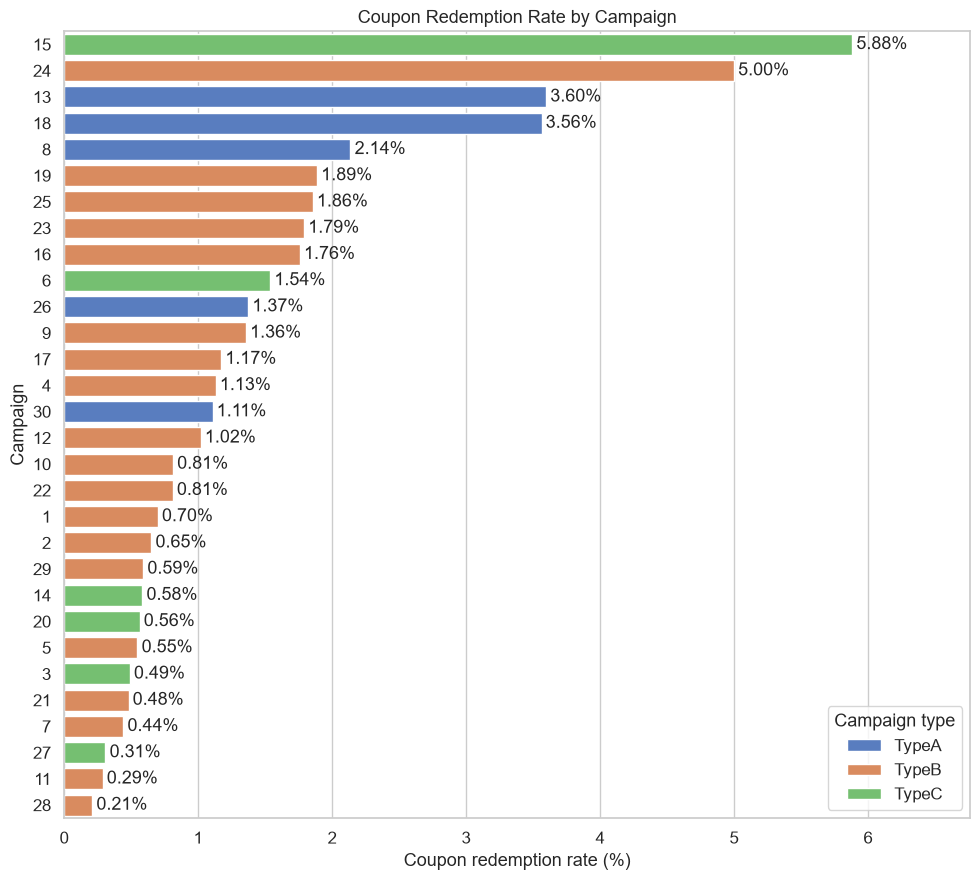

In [118]:
# Visualize coupon redemption rates by campaign
plt.figure(figsize=(10, 9))

ax = sns.barplot(
    data=campaign_redemption,
    x="coupon_redemption_rate",
    y="campaign",
    hue="campaign_type",
    orient="h",
    order=campaign_redemption.sort_values(
        "coupon_redemption_rate", ascending=False
    )["campaign"],
    hue_order=["TypeA", "TypeB", "TypeC"],
    dodge=False,
    errorbar=None
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Coupon Redemption Rate by Campaign")
plt.xlabel("Coupon redemption rate (%)")
plt.ylabel("Campaign")
plt.legend(title="Campaign type")
plt.margins(x=0.15)
plt.tight_layout()
plt.show()

In [119]:
# Summarize coupon redemption by campaign type
redemption_by_type = (
    campaign_redemption
    .groupby("campaign_type")
    .agg(
        campaigns=("campaign", "nunique"),
        household_assignments=("assigned_households", "sum"),
        redeeming_households=("redeeming_households", "sum"),
        coupons_offered=("coupons_offered", "sum"),
        redeemed_coupons=("unique_redeemed_coupons", "sum"),
        mean_campaign_redemption_rate=("coupon_redemption_rate", "mean")
    )
)

# Calculate pooled redemption rates
redemption_by_type["household_redemption_rate"] = (
    100 * redemption_by_type["redeeming_households"]
    / redemption_by_type["household_assignments"]
)

redemption_by_type["coupon_redemption_rate"] = (
    100 * redemption_by_type["redeemed_coupons"]
    / redemption_by_type["coupons_offered"]
)

print(redemption_by_type.round(2))

               campaigns  household_assignments  redeeming_households  \
campaign_type                                                           
TypeA                  5                   3979                   635   
TypeB                 19                   2655                   210   
TypeC                  6                    574                    44   

               coupons_offered  redeemed_coupons  \
campaign_type                                      
TypeA                    63664              1771   
TypeB                    41106               444   
TypeC                    12511                73   

               mean_campaign_redemption_rate  household_redemption_rate  \
campaign_type                                                             
TypeA                                   2.36                      15.96   
TypeB                                   1.18                       7.91   
TypeC                                   1.56                       7.67  

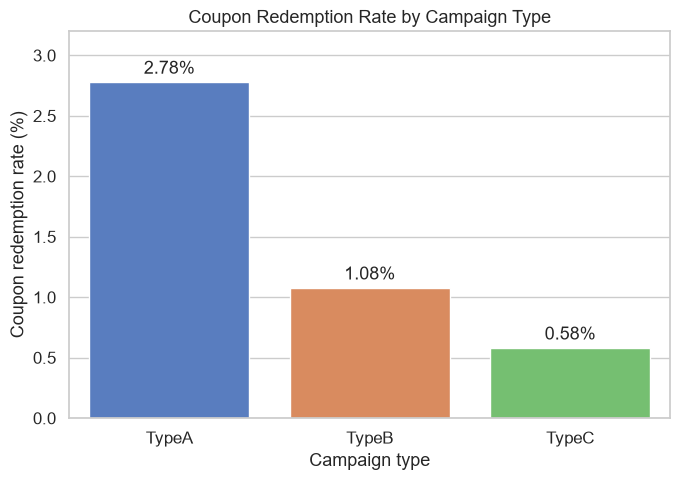

In [120]:
# Compare coupon redemption rates across campaign types
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=redemption_by_type.reset_index(),
    x="campaign_type",
    y="coupon_redemption_rate",
    hue="campaign_type",
    legend=False,
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Coupon Redemption Rate by Campaign Type")
plt.xlabel("Campaign type")
plt.ylabel("Coupon redemption rate (%)")
plt.margins(y=0.15)
plt.tight_layout()
plt.show()

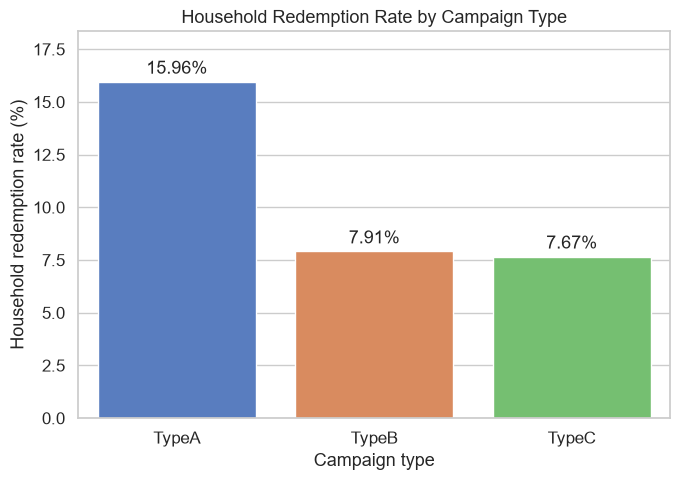

In [121]:
# Compare household redemption rates across campaign types
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=redemption_by_type.reset_index(),
    x="campaign_type",
    y="household_redemption_rate",
    hue="campaign_type",
    legend=False,
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Household Redemption Rate by Campaign Type")
plt.xlabel("Campaign type")
plt.ylabel("Household redemption rate (%)")
plt.margins(y=0.15)
plt.tight_layout()
plt.show()

In [122]:
# Examine relationships between campaign characteristics and coupon redemption
redemption_correlation = campaign_redemption[
    [
        "duration_days",
        "assigned_households",
        "coupons_per_household",
        "household_redemption_rate",
        "coupon_redemption_rate"
    ]
].corr(method="spearman")

display(redemption_correlation.round(3))

,duration_days,assigned_households,coupons_per_household,household_redemption_rate,coupon_redemption_rate
duration_days,1.000,0.016,0.290,0.258,-0.094
assigned_households,0.016,1.000,0.093,0.285,0.305
coupons_per_household,0.290,0.093,1.000,0.320,-0.363
household_redemption_rate,0.258,0.285,0.320,1.000,0.584
coupon_redemption_rate,-0.094,0.305,-0.363,0.584,1.000


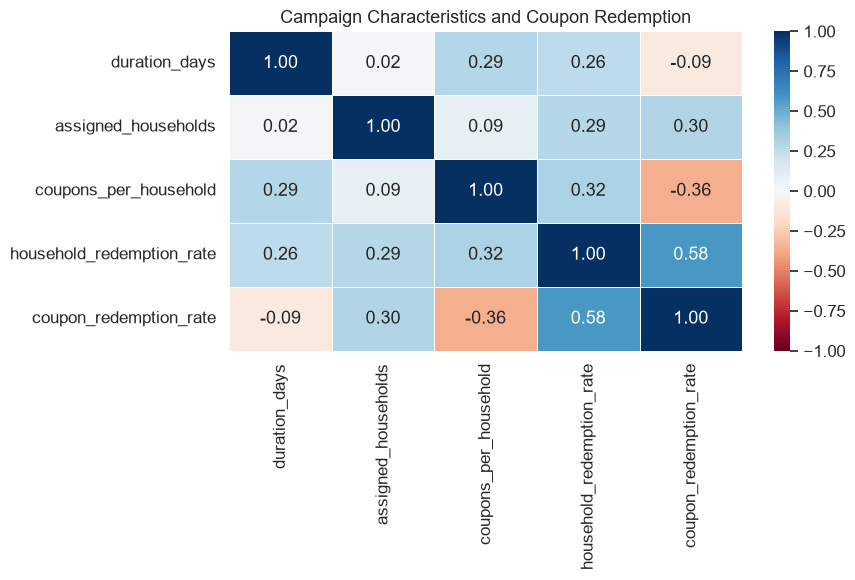

In [123]:
# Visualize campaign characteristics and redemption correlations
plt.figure(figsize=(9, 6))

sns.heatmap(
    redemption_correlation,
    annot=True,
    fmt=".2f",
    cmap="RdBu",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Campaign Characteristics and Coupon Redemption")
plt.tight_layout()
plt.show()

In [124]:
# Combine coupon redemption with eligible product sales changes
redemption_sales = campaign_redemption.merge(
    product_gap_summary.loc[
        product_gap_summary["product_scope"] == "eligible_sales_gap",
        [
            "campaign",
            "change_during",
            "change_week19",
            "change_4w"
        ]
    ],
    on="campaign",
    validate="one_to_one"
)

# Calculate correlations between redemption and sales changes
redemption_sales_correlation = redemption_sales[
    [
        "coupon_redemption_rate",
        "household_redemption_rate",
        "change_during",
        "change_week19",
        "change_4w"
    ]
].corr(method="spearman")

print(
    redemption_sales_correlation.loc[
        ["coupon_redemption_rate", "household_redemption_rate"],
        ["change_during", "change_week19", "change_4w"]
    ].round(3)
)

                           change_during  change_week19  change_4w
coupon_redemption_rate             0.689          0.172      0.061
household_redemption_rate          0.481          0.083      0.325


In [125]:
# Identify product categories associated with each coupon
coupon_categories = read_query("""
    SELECT DISTINCT
        b.campaign,
        b.coupon_upc,
        p.department,
        p.commodity_desc
    FROM analytics.bridge_coupon_product AS b
    JOIN analytics.dim_product AS p
        ON b.product_id = p.product_id;
""")

display(coupon_categories.head(10))

,campaign,coupon_upc,department,commodity_desc
0,18,10000085475,CHEF SHOPPE,UNKNOWN
1,26,51111074642,GROCERY,FRZN BREAKFAST FOODS
2,23,10000085491,NUTRITION,CHIPS&SNACKS
3,8,10000085362,PRODUCE,VEGETABLES - ALL OTHERS
4,17,53800030050,GROCERY,FRZN BREAKFAST FOODS
5,8,10000089035,GROCERY,FRZN BREAKFAST FOODS
6,23,55928320070,NUTRITION,PREPARED/PKGD FOODS
7,8,10000085363,MEAT,(CORP USE ONLY)
8,13,10000089135,GROCERY,FRZN NOVELTIES/WTR ICE
9,18,10000085476,GROCERY,MARGARINES


In [126]:
# Count product categories per coupon
coupon_category_counts = (
    coupon_categories
    .groupby(["campaign", "coupon_upc"], as_index=False)
    .agg(
        category_count=("commodity_desc", "size"),
        department=("department", "first"),
        commodity_desc=("commodity_desc", "first")
    )
)

# Identify coupons spanning multiple categories
coupon_category_counts.loc[
    coupon_category_counts["category_count"] > 1,
    ["department", "commodity_desc"]
] = "Multiple categories"

print(coupon_category_counts["category_count"].value_counts().sort_index())

category_count
1     1171
2      156
3       42
4        6
5        2
6        2
11       2
12       1
14       2
23       1
24       2
33       1
35       2
49       2
76       1
85       1
86       1
89       1
90       1
Name: count, dtype: int64


In [127]:
# Count unique household redemptions per coupon
coupon_redemption_counts = read_query("""
    SELECT
        campaign,
        coupon_upc,
        COUNT(*) AS redemption_events,
        COUNT(DISTINCT household_key) AS redeemed_coupons

    FROM analytics.fact_coupon_redemption

    GROUP BY
        campaign,
        coupon_upc;
""")

In [128]:
# Combine coupon categories with redemption counts
coupon_category_analysis = coupon_category_counts.merge(
    coupon_redemption_counts,
    on=["campaign", "coupon_upc"],
    how="left",
    validate="one_to_one"
)

coupon_category_analysis[
    ["redemption_events", "redeemed_coupons"]
] = coupon_category_analysis[
    ["redemption_events", "redeemed_coupons"]
].fillna(0)

# Add campaign characteristics
coupon_category_analysis = coupon_category_analysis.merge(
    campaign_overview[
        ["campaign", "campaign_type", "assigned_households"]
    ],
    on="campaign",
    validate="many_to_one"
)

In [129]:
# Determine coupon-level offer counts where identifiable
coupon_category_analysis["coupons_offered"] = (
    coupon_category_analysis["assigned_households"].where(
        coupon_category_analysis["campaign_type"] != "TypeA"
    )
)

In [130]:
# Summarize coupon redemption by campaign type and product category
category_redemption = (
    coupon_category_analysis
    .groupby(
        ["campaign_type", "department", "commodity_desc"],
        as_index=False,
        dropna=False
    )
    .agg(
        campaigns=("campaign", "nunique"),
        coupon_pool_size=("coupon_upc", "size"),
        redeemed_coupons=("redeemed_coupons", "sum"),
        coupons_offered=("coupons_offered", "sum")
    )
)

# Mark unknown category-level offer counts for personalized campaigns
category_redemption.loc[
    category_redemption["campaign_type"] == "TypeA",
    "coupons_offered"
] = float("nan")

# Calculate category-level redemption rates
category_redemption["coupon_redemption_rate"] = (
    100 * category_redemption["redeemed_coupons"]
    / category_redemption["coupons_offered"].where(
        category_redemption["coupons_offered"] > 0
    )
)

print(
    category_redemption
    .sort_values("redeemed_coupons", ascending=False)
    .head(20)
    .round(2)
)

    campaign_type           department            commodity_desc  campaigns  \
131         TypeA  Multiple categories       Multiple categories          5   
226         TypeB  Multiple categories       Multiple categories         18   
89          TypeA              GROCERY    ICE CREAM/MILK/SHERBTS          5   
58          TypeA              GROCERY               COLD CEREAL          5   
55          TypeA              GROCERY                    CHEESE          5   
105         TypeA              GROCERY  REFRGRATD DOUGH PRODUCTS          5   
93          TypeA              GROCERY                MARGARINES          4   
74          TypeA              GROCERY       FLUID MILK PRODUCTS          4   
102         TypeA              GROCERY    PICKLE/RELISH/PKLD VEG          5   
48          TypeA              GROCERY              BATH TISSUES          3   
106         TypeA              GROCERY    REFRGRATD JUICES/DRNKS          5   
76          TypeA              GROCERY       FROZEN 

In [131]:
# Validate coupon redemption and offer totals
(print(
    category_redemption
    .groupby("campaign_type")[
        ["redeemed_coupons", "coupons_offered"]
    ]
    .sum(min_count=1)
))

               redeemed_coupons  coupons_offered
campaign_type                                   
TypeA                    1771.0              NaN
TypeB                     444.0          41106.0
TypeC                      73.0          12511.0


In [132]:
# Select categories with the highest coupon offer counts
top_coupon_categories = (
    category_redemption.loc[
        (category_redemption["campaign_type"] != "TypeA")
        & (category_redemption["department"] != "Multiple categories")
    ]
    .groupby(["department", "commodity_desc"], as_index=False)
    .agg(coupons_offered=("coupons_offered", "sum"))
    .nlargest(10, "coupons_offered")
)

display(top_coupon_categories)

,department,commodity_desc,coupons_offered
53,GROCERY,FRZN MEAT/MEAT DINNERS,2160.0
24,DRUG GM,SOAP - LIQUID & BAR,1904.0
37,GROCERY,CHEESE,1856.0
17,DRUG GM,HAND/BODY/FACIAL PRODUCTS,1720.0
21,DRUG GM,ORAL HYGIENE PRODUCTS,1386.0
3,DRUG GM,BABY FOODS,1380.0
71,GROCERY,REFRGRATD JUICES/DRNKS,1306.0
48,GROCERY,FROZEN BREAD/DOUGH,1254.0
62,GROCERY,LAUNDRY DETERGENTS,1131.0
19,DRUG GM,INFANT FORMULA,1011.0


In [133]:
# Prepare category redemption rates for comparison
category_redemption_comparison = category_redemption.loc[
    category_redemption["campaign_type"] != "TypeA"
].merge(
    top_coupon_categories[["department", "commodity_desc"]],
    on=["department", "commodity_desc"],
    validate="many_to_one"
)

# Create unique category labels
category_redemption_comparison["category"] = (
    category_redemption_comparison["department"]
    + " / "
    + category_redemption_comparison["commodity_desc"]
)

print(category_redemption_comparison.round(2))

   campaign_type department             commodity_desc  campaigns  \
0          TypeB    DRUG GM                 BABY FOODS          3   
1          TypeB    DRUG GM             INFANT FORMULA          3   
2          TypeB    DRUG GM      ORAL HYGIENE PRODUCTS          4   
3          TypeB    DRUG GM        SOAP - LIQUID & BAR          3   
4          TypeB    GROCERY                     CHEESE         11   
5          TypeB    GROCERY         FROZEN BREAD/DOUGH          3   
6          TypeB    GROCERY     FRZN MEAT/MEAT DINNERS          7   
7          TypeB    GROCERY         LAUNDRY DETERGENTS          1   
8          TypeB    GROCERY     REFRGRATD JUICES/DRNKS          8   
9          TypeC    DRUG GM  HAND/BODY/FACIAL PRODUCTS          3   
10         TypeC    DRUG GM      ORAL HYGIENE PRODUCTS          1   
11         TypeC    DRUG GM        SOAP - LIQUID & BAR          4   
12         TypeC    GROCERY         LAUNDRY DETERGENTS          4   

    coupon_pool_size  redeemed_co

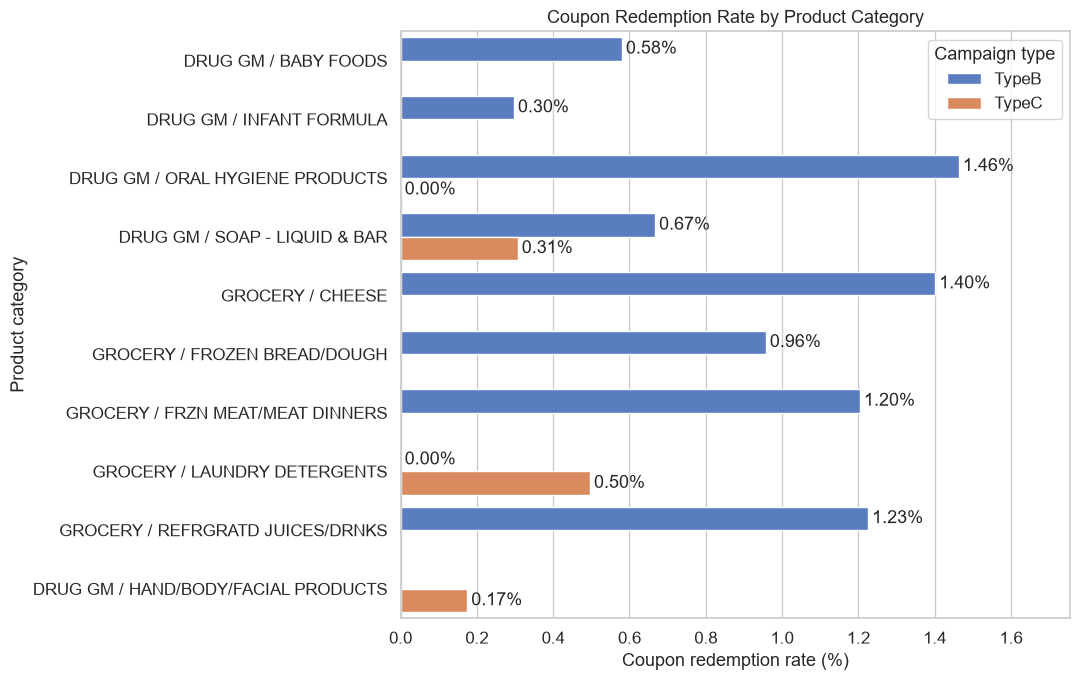

In [134]:
# Compare category redemption rates across campaign types
plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=category_redemption_comparison,
    x="coupon_redemption_rate",
    y="category",
    hue="campaign_type",
    hue_order=["TypeB", "TypeC"],
    errorbar=None
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Coupon Redemption Rate by Product Category")
plt.xlabel("Coupon redemption rate (%)")
plt.ylabel("Product category")
plt.legend(title="Campaign type")
plt.margins(x=0.2)
plt.tight_layout()
plt.show()

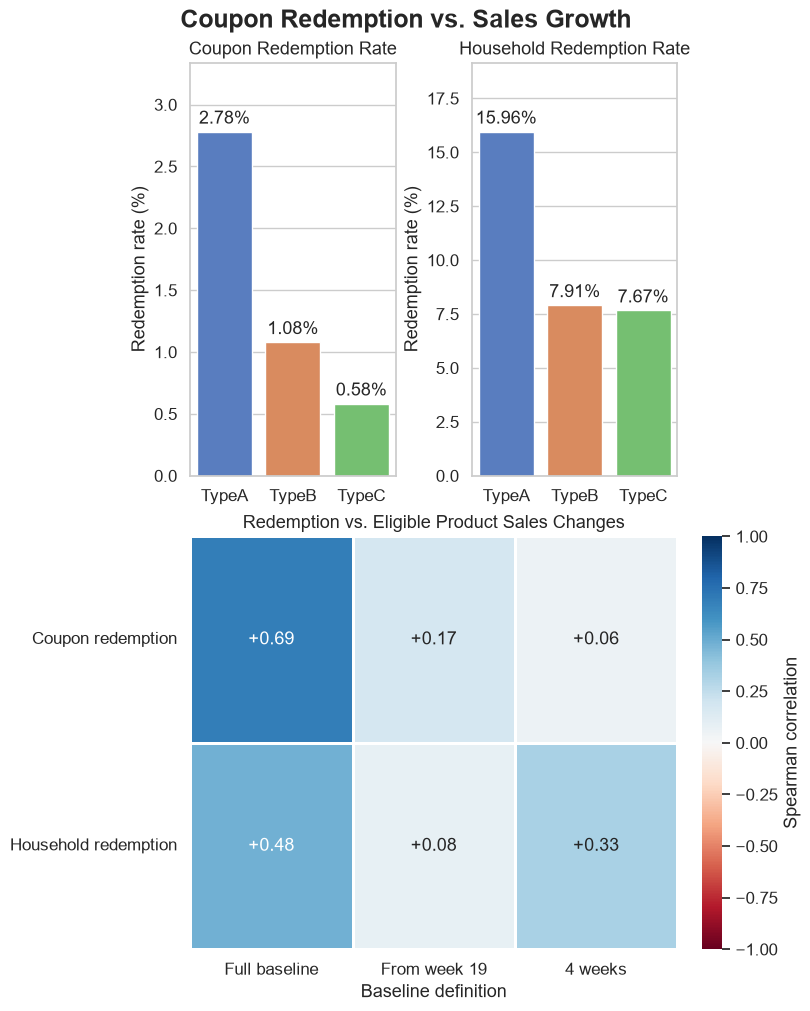

In [135]:
# Prepare redemption and sales correlation matrix
redemption_heatmap = redemption_sales_correlation.loc[
    ["coupon_redemption_rate", "household_redemption_rate"],
    ["change_during", "change_week19", "change_4w"]
].rename(
    index={
        "coupon_redemption_rate": "Coupon redemption",
        "household_redemption_rate": "Household redemption"
    },
    columns={
        "change_during": "Full baseline",
        "change_week19": "From week 19",
        "change_4w": "4 weeks"
    }
)

# Create a combined visualization layout
fig, axes = plt.subplot_mosaic(
    [
        ["coupon", "household"],
        ["correlation", "correlation"]
    ],
    figsize=(8, 10),
    layout="constrained"
)

# Visualize coupon redemption rates
sns.barplot(
    data=redemption_by_type.reset_index(),
    x="campaign_type",
    y="coupon_redemption_rate",
    hue="campaign_type",
    hue_order=["TypeA", "TypeB", "TypeC"],
    legend=False,
    errorbar=None,
    ax=axes["coupon"]
)

for container in axes["coupon"].containers:
    axes["coupon"].bar_label(
        container, fmt="%.2f%%", padding=3
    )

axes["coupon"].set_title("Coupon Redemption Rate")
axes["coupon"].set_xlabel("")
axes["coupon"].set_ylabel("Redemption rate (%)")
axes["coupon"].margins(y=0.2)

# Visualize household redemption rates
sns.barplot(
    data=redemption_by_type.reset_index(),
    x="campaign_type",
    y="household_redemption_rate",
    hue="campaign_type",
    hue_order=["TypeA", "TypeB", "TypeC"],
    legend=False,
    errorbar=None,
    ax=axes["household"]
)

for container in axes["household"].containers:
    axes["household"].bar_label(
        container, fmt="%.2f%%", padding=3
    )

axes["household"].set_title("Household Redemption Rate")
axes["household"].set_xlabel("")
axes["household"].set_ylabel("Redemption rate (%)")
axes["household"].margins(y=0.2)

# Visualize correlations with eligible product sales changes
sns.heatmap(
    redemption_heatmap,
    annot=True,
    fmt="+.2f",
    cmap="RdBu",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=1,
    cbar_kws={"label": "Spearman correlation"},
    ax=axes["correlation"]
)

axes["correlation"].set_title(
    "Redemption vs. Eligible Product Sales Changes"
)
axes["correlation"].set_xlabel("Baseline definition")
axes["correlation"].set_ylabel("")
axes["correlation"].tick_params(axis="x", rotation=0)
axes["correlation"].tick_params(axis="y", rotation=0)

fig.suptitle(
    "Coupon Redemption vs. Sales Growth",
    fontsize=18,
    fontweight="bold"
)

plt.show()

## 2.13 Product Trial Analysis

In [139]:
# Retrieve coupon redemption events and verify transaction availability
redemption_events = read_query("""
    SELECT
        r.household_key,
        r.campaign,
        r.coupon_upc,
        r.day,
        EXISTS (
            SELECT 1
            FROM analytics.fact_sales AS s
            WHERE s.household_key = r.household_key
              AND s.day = r.day
        ) AS has_same_day_purchase
    FROM analytics.fact_coupon_redemption AS r;
""")

print(redemption_events.head(10))


   household_key  campaign   coupon_upc  day  has_same_day_purchase
0              1         8  10000085364  421                   True
1              1         8  51700010076  421                   True
2              1         8  54200000033  427                   True
3              1        18  10000085476  597                   True
4              1        18  54200029176  597                   True
5              8         8  53600000078  422                   True
6             13         5  53700048182  396                   True
7             13         8  10000085364  424                   True
8             13         8  53600000078  434                   True
9             13         8  52370020076  447                   True


In [137]:

print("Redemption events:", len(redemption_events))
print("First redemption day:", redemption_events["day"].min())
print("Last redemption day:", redemption_events["day"].max())
print("Events with same-day purchases:",
      redemption_events["has_same_day_purchase"].sum())

Redemption events: 2318
First redemption day: 225
Last redemption day: 704
Events with same-day purchases: 2318


In [140]:
# Identify candidate transaction lines for each redemption event
coupon_purchase_candidates = read_query("""
    SELECT
        r.household_key,
        r.campaign,
        r.coupon_upc,
        r.day,
        s.basket_id,
        s.product_id,
        p.department,
        p.commodity_desc,
        s.quantity,
        s.sales_value,
        s.retail_disc,
        s.coupon_disc,
        s.coupon_match_disc

    FROM analytics.fact_coupon_redemption AS r

    JOIN analytics.bridge_coupon_product AS b
        ON r.campaign = b.campaign
        AND r.coupon_upc = b.coupon_upc

    JOIN analytics.fact_sales AS s
        ON r.household_key = s.household_key
        AND r.day = s.day
        AND b.product_id = s.product_id

    JOIN analytics.dim_product AS p
        ON s.product_id = p.product_id;
""")

print(coupon_purchase_candidates.head(10))



   household_key  campaign   coupon_upc  day    basket_id  product_id  \
0           2448         8  54440020034  453  33659125785     1012851   
1           2448         8  54440020034  453  33659125785     1121053   
2           1166         8  53700067076  453  33659195261     5567950   
3           1936         8  10000085363  453  33659312730    12262778   
4           2451         8  57127900036  453  33659340739     9836460   
5           2451         8  57127900036  453  33659340739    12731306   
6           2455         8  55000013033  453  33659387726      983795   
7            421         8  10000085364  453  33659582265      827332   
8            421         8  10000085364  453  33659582265      916993   
9            421         8  10000085364  453  33659582265      995242   

      department       commodity_desc  quantity  sales_value  retail_disc  \
0  SEAFOOD-PCKGD     SEAFOOD - FROZEN         1         2.50        -2.39   
1  SEAFOOD-PCKGD     SEAFOOD - FROZEN     

In [141]:
print("Candidate transaction lines:",len(coupon_purchase_candidates))

Candidate transaction lines: 4306


In [142]:
# Identify recorded coupon discounts
coupon_purchase_candidates["has_coupon_discount"] = (coupon_purchase_candidates["coupon_disc"] < 0)

coupon_purchase_candidates["has_coupon_match"] = (coupon_purchase_candidates["coupon_match_disc"] < 0)

# Identify transaction lines shared by multiple redemption events
coupon_purchase_candidates["shared_candidate"] = (coupon_purchase_candidates.duplicated(subset=["household_key", "day", "basket_id", "product_id"], keep=False))

In [143]:
# Define the redemption event grain
redemption_key = [
    "household_key",
    "campaign",
    "coupon_upc",
    "day"
]

# Summarize candidate purchases per redemption event
redemption_candidates = (
    coupon_purchase_candidates
    .groupby(redemption_key, as_index=False)
    .agg(
        matched_lines=("product_id", "size"),
        matched_products=("product_id", "nunique"),
        matched_baskets=("basket_id", "nunique"),
        coupon_discount_lines=("has_coupon_discount", "sum"),
        coupon_match_lines=("has_coupon_match", "sum"),
        shared_candidate_lines=("shared_candidate", "sum")
    )
)

# Preserve all redemption events
redemption_matching = redemption_events.merge(
    redemption_candidates,
    on=redemption_key,
    how="left",
    validate="one_to_one"
)

matching_columns = [
    "matched_lines",
    "matched_products",
    "matched_baskets",
    "coupon_discount_lines",
    "coupon_match_lines",
    "shared_candidate_lines"
]

redemption_matching[matching_columns] = (
    redemption_matching[matching_columns]
    .fillna(0)
    .astype(int)
)

print(redemption_matching.head(10))

   household_key  campaign   coupon_upc  day  has_same_day_purchase  \
0              1         8  10000085364  421                   True   
1              1         8  51700010076  421                   True   
2              1         8  54200000033  427                   True   
3              1        18  10000085476  597                   True   
4              1        18  54200029176  597                   True   
5              8         8  53600000078  422                   True   
6             13         5  53700048182  396                   True   
7             13         8  10000085364  424                   True   
8             13         8  53600000078  434                   True   
9             13         8  52370020076  447                   True   

   matched_lines  matched_products  matched_baskets  coupon_discount_lines  \
0              3                 3                1                      0   
1              1                 1                1           

In [144]:
# Classify coupon-to-product matching results
redemption_matching["matching_status"] = "No eligible product purchase"

redemption_matching.loc[
    ~redemption_matching["has_same_day_purchase"],
    "matching_status"
] = "No same-day purchase"

redemption_matching.loc[
    redemption_matching["matched_products"] == 1,
    "matching_status"
] = "Single product candidate"

redemption_matching.loc[
    redemption_matching["matched_products"] > 1,
    "matching_status"
] = "Multiple product candidates"

# Summarize matching quality
matching_summary = (
    redemption_matching["matching_status"]
    .value_counts()
    .to_frame("redemption_events")
)

matching_summary["share_pct"] = (
    100 * matching_summary["redemption_events"]
    / len(redemption_matching)
)

print(matching_summary.round(2))

                              redemption_events  share_pct
matching_status                                           
Single product candidate                   1225      52.85
Multiple product candidates                 778      33.56
No eligible product purchase                315      13.59


In [145]:
# Assess additional matching evidence
print("Events with exactly one candidate transaction line:",(redemption_matching["matched_lines"] == 1).sum())
print("Events with exactly one coupon-discounted candidate line:",(redemption_matching["coupon_discount_lines"] == 1).sum())
print("Events with shared transaction candidates:",(redemption_matching["shared_candidate_lines"] > 0).sum())

Events with exactly one candidate transaction line: 1225
Events with exactly one coupon-discounted candidate line: 1203
Events with shared transaction candidates: 111


In [147]:
# Add event-level matching characteristics
candidate_evidence = coupon_purchase_candidates.merge(
    redemption_matching[
        redemption_key + [
            "matched_lines",
            "coupon_discount_lines"
        ]
    ],
    on=redemption_key,
    validate="many_to_one"
)

# Identify strong and weak matches
strong_match = (
    (candidate_evidence["coupon_discount_lines"] == 1)
    & candidate_evidence["has_coupon_discount"]
    & ~candidate_evidence["shared_candidate"]
    & (candidate_evidence["quantity"] > 0)
)

weak_match = (
    (candidate_evidence["matched_lines"] == 1)
    & ~candidate_evidence["has_coupon_discount"]
    & ~candidate_evidence["shared_candidate"]
    & (candidate_evidence["quantity"] > 0)
)

# Select transaction lines supported by matching evidence
selected_candidates = candidate_evidence.loc[
    strong_match | weak_match
].copy()

selected_candidates["matching_evidence"] = "Weak match"

selected_candidates.loc[
    selected_candidates["has_coupon_discount"],
    "matching_evidence"
] = "Strong match"

print("Duplicated redemption events:",selected_candidates.duplicated(redemption_key).sum())

Duplicated redemption events: 0


In [148]:
# Preserve all redemption events and assign matching evidence
redemption_evidence = redemption_matching.merge(
    selected_candidates[
        redemption_key + ["matching_evidence"]
    ],
    on=redemption_key,
    how="left",
    validate="one_to_one"
)

redemption_evidence["matching_evidence"] = (
    redemption_evidence["matching_evidence"]
    .fillna("Unresolved")
)

redemption_evidence.loc[
    redemption_evidence["matched_lines"] == 0,
    "matching_evidence"
] = "No eligible purchase"

# Summarize matching evidence
evidence_summary = (
    redemption_evidence["matching_evidence"]
    .value_counts()
    .to_frame("redemption_events")
)

evidence_summary["share_pct"] = (
    100 * evidence_summary["redemption_events"]
    / len(redemption_evidence)
)

print(evidence_summary.round(2))

                      redemption_events  share_pct
matching_evidence                                 
Strong match                       1132      48.84
Unresolved                          518      22.35
Weak match                          353      15.23
No eligible purchase                315      13.59


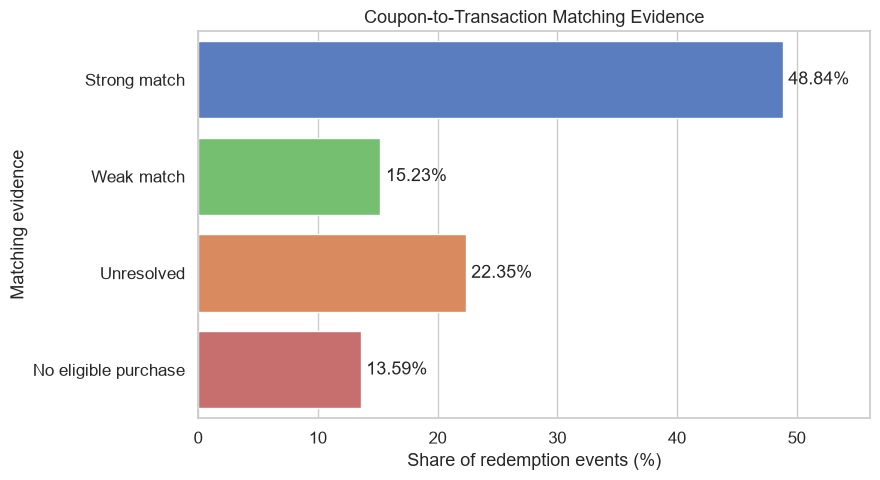

In [149]:
# Visualize coupon-to-transaction matching evidence
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=evidence_summary.reset_index(),
    x="share_pct",
    y="matching_evidence",
    hue="matching_evidence",
    order=[
        "Strong match",
        "Weak match",
        "Unresolved",
        "No eligible purchase"
    ],
    legend=False,
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=4)

plt.title("Coupon-to-Transaction Matching Evidence")
plt.xlabel("Share of redemption events (%)")
plt.ylabel("Matching evidence")
plt.margins(x=0.15)
plt.tight_layout()
plt.show()

In [150]:
# Retrieve prior purchase history for candidate products
candidate_purchase_history = read_query("""
    WITH candidate_products AS (
        SELECT DISTINCT
            r.household_key,
            r.day,
            s.product_id
        FROM analytics.fact_coupon_redemption AS r
        JOIN analytics.bridge_coupon_product AS b
            ON r.campaign = b.campaign
            AND r.coupon_upc = b.coupon_upc
        JOIN analytics.fact_sales AS s
            ON r.household_key = s.household_key
            AND r.day = s.day
            AND b.product_id = s.product_id
        WHERE s.quantity > 0
    ),

    household_history AS (
        SELECT
            household_key,
            MIN(day) AS first_household_purchase_day
        FROM analytics.fact_sales
        WHERE quantity > 0
        GROUP BY household_key
    ),

    product_history AS (
        SELECT
            c.household_key,
            c.product_id,
            c.day,
            COUNT(DISTINCT s.day) AS prior_purchase_days,
            MIN(s.day) AS first_prior_purchase_day,
            MAX(s.day) AS last_prior_purchase_day
        FROM candidate_products AS c
        LEFT JOIN analytics.fact_sales AS s
            ON c.household_key = s.household_key
            AND c.product_id = s.product_id
            AND s.day < c.day
            AND s.quantity > 0
        GROUP BY
            c.household_key,
            c.product_id,
            c.day
    )

    SELECT
        p.*,
        h.first_household_purchase_day
    FROM product_history AS p
    JOIN household_history AS h
        ON p.household_key = h.household_key;
""")

display(candidate_purchase_history.head(10))

,household_key,product_id,day,prior_purchase_days,first_prior_purchase_day,last_prior_purchase_day,first_household_purchase_day
0,1,840361,421,5,51.0,274.0,51
1,1,865456,597,4,235.0,472.0,51
2,1,872137,597,2,235.0,464.0,51
3,1,995242,421,20,88.0,412.0,51
4,1,995242,597,29,88.0,568.0,51
5,1,1025641,597,4,203.0,588.0,51
6,1,1046816,597,0,NaN,NaN,51
7,1,5577022,421,10,51.0,375.0,51
8,1,6391068,421,4,128.0,324.0,51
9,1,9297615,597,18,67.0,568.0,51


In [151]:
# Identify products not previously purchased in the observed history
candidate_purchase_history["product_trial"] = (candidate_purchase_history["prior_purchase_days"] == 0)

# Calculate available household purchase history
candidate_purchase_history["history_days"] = (candidate_purchase_history["day"] - candidate_purchase_history["first_household_purchase_day"])

# Calculate time since the previous product purchase
candidate_purchase_history["days_since_last_purchase"] = (candidate_purchase_history["day"] - candidate_purchase_history["last_prior_purchase_day"])

print(candidate_purchase_history.head(10))

   household_key  product_id  day  prior_purchase_days  \
0              1      840361  421                    5   
1              1      865456  597                    4   
2              1      872137  597                    2   
3              1      995242  421                   20   
4              1      995242  597                   29   
5              1     1025641  597                    4   
6              1     1046816  597                    0   
7              1     5577022  421                   10   
8              1     6391068  421                    4   
9              1     9297615  597                   18   

   first_prior_purchase_day  last_prior_purchase_day  \
0                      51.0                    274.0   
1                     235.0                    472.0   
2                     235.0                    464.0   
3                      88.0                    412.0   
4                      88.0                    568.0   
5                     203

In [152]:
# Combine selected purchases with prior purchase history
selected_trial = selected_candidates.merge(
    candidate_purchase_history,
    on=["household_key", "product_id", "day"],
    validate="many_to_one"
)

# Summarize product trial by matching evidence
trial_by_evidence = (
    selected_trial
    .groupby("matching_evidence")
    .agg(
        redemption_events=("product_trial", "size"),
        new_product_purchases=("product_trial", "sum"),
        median_history_days=("history_days", "median")
    )
)

# Calculate product trial rate
trial_by_evidence["product_trial_rate"] = (100 * trial_by_evidence["new_product_purchases"] / trial_by_evidence["redemption_events"])

print(trial_by_evidence.round(2))

                   redemption_events  new_product_purchases  \
matching_evidence                                             
Strong match                    1132                    496   
Weak match                       353                    128   

                   median_history_days  product_trial_rate  
matching_evidence                                           
Strong match                     480.5               43.82  
Weak match                       466.0               36.26  


In [153]:
# Combine all positive-quantity candidates with purchase history
all_candidate_trials = coupon_purchase_candidates.loc[
    coupon_purchase_candidates["quantity"] > 0
].merge(
    candidate_purchase_history,
    on=["household_key", "product_id", "day"],
    validate="many_to_one"
)

# Assess product trial across all candidates per redemption
trial_uncertainty = (
    all_candidate_trials
    .groupby(redemption_key, as_index=False)
    .agg(
        all_products_new=("product_trial", "all"),
        any_product_new=("product_trial", "any")
    )
)

# Preserve all redemption events
redemption_trial_status = redemption_evidence.merge(
    trial_uncertainty,
    on=redemption_key,
    how="left",
    validate="one_to_one"
)

# Classify product trial uncertainty
redemption_trial_status["trial_status"] = (
    "Mixed candidate history"
)

redemption_trial_status.loc[
    redemption_trial_status["all_products_new"].eq(True),
    "trial_status"
] = "All candidates new"

redemption_trial_status.loc[
    redemption_trial_status["any_product_new"].eq(False),
    "trial_status"
] = "All candidates previously purchased"

redemption_trial_status.loc[
    redemption_trial_status["any_product_new"].isna(),
    "trial_status"
] = "No positive eligible candidate"

# Summarize product trial uncertainty
trial_uncertainty_summary = pd.crosstab(
    redemption_trial_status["matching_evidence"],
    redemption_trial_status["trial_status"],
    margins=True
)

print(trial_uncertainty_summary)

trial_status          All candidates new  All candidates previously purchased  \
matching_evidence                                                               
No eligible purchase                   0                                    0   
Strong match                         433                                  573   
Unresolved                            75                                  171   
Weak match                           128                                  225   
All                                  636                                  969   

trial_status          Mixed candidate history  No positive eligible candidate  \
matching_evidence                                                               
No eligible purchase                        0                             315   
Strong match                              126                               0   
Unresolved                                272                               0   
Weak match                 

In [154]:
# Add campaign type to selected product purchases
selected_trial = selected_trial.merge(
    campaign_overview[["campaign", "campaign_type"]],
    on="campaign",
    validate="many_to_one"
)

# Summarize product trial by campaign type and matching evidence
trial_by_type = (
    selected_trial
    .groupby(["campaign_type", "matching_evidence"], as_index=False)
    .agg(
        campaigns=("campaign", "nunique"),
        households=("household_key", "nunique"),
        redemption_events=("product_trial", "size"),
        new_product_purchases=("product_trial", "sum"),
        median_history_days=("history_days", "median")
    )
)

# Calculate product trial rate
trial_by_type["product_trial_rate"] = (
    100 * trial_by_type["new_product_purchases"]
    / trial_by_type["redemption_events"]
)

print(trial_by_type.round(2))

  campaign_type matching_evidence  campaigns  households  redemption_events  \
0         TypeA      Strong match          5         281                854   
1         TypeA        Weak match          5         169                279   
2         TypeB      Strong match         19         101                239   
3         TypeB        Weak match         14          51                 69   
4         TypeC      Strong match          6          29                 39   
5         TypeC        Weak match          3           5                  5   

   new_product_purchases  median_history_days  product_trial_rate  
0                    360                469.0               42.15  
1                     92                461.0               32.97  
2                    117                533.0               48.95  
3                     33                472.0               47.83  
4                     19                533.0               48.72  
5                      3              

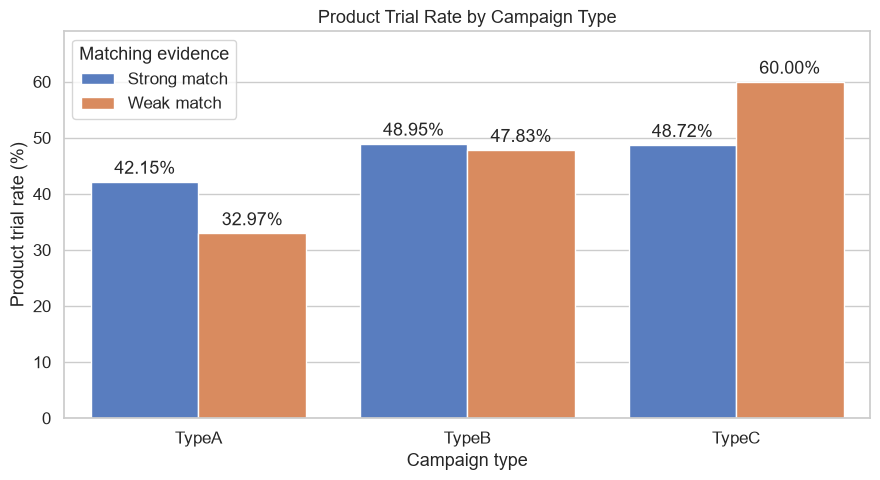

In [155]:
# Compare product trial rates across campaign types
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=trial_by_type,
    x="campaign_type",
    y="product_trial_rate",
    hue="matching_evidence",
    hue_order=["Strong match", "Weak match"],
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Product Trial Rate by Campaign Type")
plt.xlabel("Campaign type")
plt.ylabel("Product trial rate (%)")
plt.legend(title="Matching evidence")
plt.margins(y=0.15)
plt.tight_layout()
plt.show()

In [156]:
# Add campaign type to all redemption events
trial_bounds_data = redemption_trial_status.merge(
    campaign_overview[["campaign", "campaign_type"]],
    on="campaign",
    validate="many_to_one"
)

# Identify lower and upper trial scenarios
trial_bounds_data["has_candidate"] = (
    trial_bounds_data["any_product_new"].notna()
)

trial_bounds_data["lower_trial"] = (
    trial_bounds_data["all_products_new"].eq(True)
)

trial_bounds_data["upper_trial"] = (
    trial_bounds_data["any_product_new"].eq(True)
)

# Calculate trial bounds by campaign type
trial_bounds_by_type = (
    trial_bounds_data
    .groupby("campaign_type")
    .agg(
        redemption_events=("campaign", "size"),
        matched_events=("has_candidate", "sum"),
        lower_trial_count=("lower_trial", "sum"),
        upper_trial_count=("upper_trial", "sum")
    )
)

trial_bounds_by_type["lower_trial_rate"] = (
    100 * trial_bounds_by_type["lower_trial_count"]
    / trial_bounds_by_type["matched_events"]
)

trial_bounds_by_type["upper_trial_rate"] = (
    100 * trial_bounds_by_type["upper_trial_count"]
    / trial_bounds_by_type["matched_events"]
)

print(trial_bounds_by_type.round(2))

               redemption_events  matched_events  lower_trial_count  \
campaign_type                                                         
TypeA                       1791            1581                443   
TypeB                        454             363                164   
TypeC                         73              59                 29   

               upper_trial_count  lower_trial_rate  upper_trial_rate  
campaign_type                                                         
TypeA                        804             28.02             50.85  
TypeB                        193             45.18             53.17  
TypeC                         37             49.15             62.71  


In [157]:
# Select purchases with strong matching evidence
strong_trial = selected_trial.loc[
    selected_trial["matching_evidence"] == "Strong match"
].copy()

# Compare results across minimum purchase history requirements
trial_history_sensitivity = pd.DataFrame({
    "Full sample": (
        strong_trial.groupby("campaign_type")["product_trial"].mean()
    ),
    "At least 180 days": (
        strong_trial.loc[strong_trial["history_days"] >= 180]
        .groupby("campaign_type")["product_trial"].mean()
    ),
    "At least 365 days": (
        strong_trial.loc[strong_trial["history_days"] >= 365]
        .groupby("campaign_type")["product_trial"].mean()
    )
}) * 100

print(trial_history_sensitivity.round(2))

               Full sample  At least 180 days  At least 365 days
campaign_type                                                   
TypeA                42.15              42.22              40.59
TypeB                48.95              48.95              46.86
TypeC                48.72              48.72              48.65


In [158]:
# Compare sample sizes across history requirements
trial_history_counts = pd.DataFrame({
    "Full sample": (
        strong_trial.groupby("campaign_type").size()
    ),
    "At least 180 days": (
        strong_trial.loc[strong_trial["history_days"] >= 180]
        .groupby("campaign_type").size()
    ),
    "At least 365 days": (
        strong_trial.loc[strong_trial["history_days"] >= 365]
        .groupby("campaign_type").size()
    )
}).fillna(0).astype(int)

print(trial_history_counts)

               Full sample  At least 180 days  At least 365 days
campaign_type                                                   
TypeA                  854                848                675
TypeB                  239                239                207
TypeC                   39                 39                 37


In [159]:
# Summarize product trial by product category
trial_by_category = (
    strong_trial
    .groupby(["department", "commodity_desc"], as_index=False)
    .agg(
        campaigns=("campaign", "nunique"),
        households=("household_key", "nunique"),
        redemption_events=("product_trial", "size"),
        new_product_purchases=("product_trial", "sum"),
        median_history_days=("history_days", "median")
    )
)

# Calculate category-level product trial rate
trial_by_category["product_trial_rate"] = (
    100 * trial_by_category["new_product_purchases"]
    / trial_by_category["redemption_events"]
)

print(
    trial_by_category
    .sort_values("redemption_events", ascending=False)
    .head(20)
    .round(2)
)

    department            commodity_desc  campaigns  households  \
66     GROCERY    ICE CREAM/MILK/SHERBTS          6          62   
39     GROCERY               COLD CEREAL          8          43   
56     GROCERY              FROZEN PIZZA          8          43   
36     GROCERY                    CHEESE         11          37   
70     GROCERY                MARGARINES          6          39   
80     GROCERY  REFRGRATD DOUGH PRODUCTS          6          34   
59     GROCERY    FRZN MEAT/MEAT DINNERS          8          35   
30     GROCERY              BATH TISSUES          4          32   
86     GROCERY               SOFT DRINKS          6          28   
81     GROCERY    REFRGRATD JUICES/DRNKS          7          25   
91     GROCERY                    YOGURT          5          24   
77     GROCERY    PICKLE/RELISH/PKLD VEG          4          22   
76     GROCERY               PASTA SAUCE          6          20   
26     GROCERY                BAG SNACKS          7          1

In [161]:
# Examine matching evidence across campaign types
matching_by_type = pd.crosstab(
    redemption_evidence.merge(
        campaign_overview[["campaign", "campaign_type"]],
        on="campaign",
        validate="many_to_one"
    )["campaign_type"],
    redemption_evidence["matching_evidence"]
)

print(matching_by_type)

matching_evidence  No eligible purchase  Strong match  Unresolved  Weak match
campaign_type                                                                
TypeA                               210           854         448         279
TypeB                                91           239          55          69
TypeC                                14            39          15           5


In [163]:
# Calculate matching evidence shares within campaign types
matching_by_type_pct = (
    matching_by_type.div(
        matching_by_type.sum(axis=1),
        axis=0
    ) * 100
)

print(matching_by_type_pct.round(2))

matching_evidence  No eligible purchase  Strong match  Unresolved  Weak match
campaign_type                                                                
TypeA                             11.73         47.68       25.01       15.58
TypeB                             20.04         52.64       12.11       15.20
TypeC                             19.18         53.42       20.55        6.85


In [164]:
# Examine discounts on weakly matched transaction lines
weak_candidates = selected_candidates.loc[
    selected_candidates["matching_evidence"] == "Weak match"
].copy()

weak_discount_summary = pd.DataFrame({
    "transaction_lines": {
        "Manufacturer coupon discount":
            (weak_candidates["coupon_disc"] < 0).sum(),

        "Retailer coupon match":
            (weak_candidates["coupon_match_disc"] < 0).sum(),

        "Loyalty discount":
            (weak_candidates["retail_disc"] < 0).sum(),

        "No recorded discount":
            (
                (weak_candidates["coupon_disc"] == 0)
                & (weak_candidates["coupon_match_disc"] == 0)
                & (weak_candidates["retail_disc"] == 0)
            ).sum()
    }
})

weak_discount_summary["share_pct"] = (100 * weak_discount_summary["transaction_lines"] / len(weak_candidates))

print(weak_discount_summary.round(2))

                              transaction_lines  share_pct
Manufacturer coupon discount                  0       0.00
Retailer coupon match                         0       0.00
Loyalty discount                            288      81.59
No recorded discount                         65      18.41


In [165]:
# Retrieve basket-level discount information on redemption days
redemption_day_baskets = read_query("""
    WITH redemption_days AS (
        SELECT DISTINCT
            household_key,
            day
        FROM analytics.fact_coupon_redemption
    )

    SELECT
        s.household_key,
        s.day,
        s.basket_id,
        COUNT(*) AS basket_lines,
        COUNT(*) FILTER (
            WHERE s.coupon_disc < 0
        ) AS coupon_discount_lines,
        COUNT(*) FILTER (
            WHERE s.coupon_match_disc < 0
        ) AS coupon_match_lines
    FROM analytics.fact_sales AS s
    JOIN redemption_days AS r
        ON s.household_key = r.household_key
        AND s.day = r.day
    GROUP BY
        s.household_key,
        s.day,
        s.basket_id;
""")

In [166]:
# Check whether other basket lines received coupon discounts
weak_basket_analysis = weak_candidates.merge(
    redemption_day_baskets,
    on=["household_key", "day", "basket_id"],
    validate="many_to_one",
    suffixes=("", "_basket")
)

print("Weak matches:", len(weak_basket_analysis))

print("Weak matches with another coupon-discounted basket line:",(weak_basket_analysis["coupon_discount_lines_basket"] > 0).sum())

Weak matches: 353
Weak matches with another coupon-discounted basket line: 294


In [168]:
# Aggregate coupon discounts across redemption days
redemption_day_discounts = (
    redemption_day_baskets
    .groupby(["household_key", "day"], as_index=False)
    .agg(
        daily_coupon_discount_lines=("coupon_discount_lines", "sum"),
        daily_coupon_match_lines=("coupon_match_lines", "sum")
    )
)

# Examine unmatched redemptions
unmatched_redemptions = redemption_evidence.loc[
    redemption_evidence["matching_evidence"] == "No eligible purchase"
].merge(
    redemption_day_discounts,
    on=["household_key", "day"],
    validate="many_to_one"
)

print("Unmatched redemptions:", len(unmatched_redemptions))

print("Unmatched redemptions with same-day coupon discounts:",(unmatched_redemptions["daily_coupon_discount_lines"] > 0).sum())

Unmatched redemptions: 315
Unmatched redemptions with same-day coupon discounts: 293


In [169]:
# Identify the first observed purchase in each product category
household_category_history = read_query("""
    SELECT
        s.household_key,
        p.department,
        p.commodity_desc,
        MIN(s.day) AS first_category_purchase_day
    FROM analytics.fact_sales AS s
    JOIN analytics.dim_product AS p
        ON s.product_id = p.product_id
    WHERE s.quantity > 0
        AND EXISTS (
            SELECT 1
            FROM analytics.fact_coupon_redemption AS r
            WHERE r.household_key = s.household_key
        )
    GROUP BY
        s.household_key,
        p.department,
        p.commodity_desc;
""")

display(household_category_history.head(10))

,household_key,department,commodity_desc,first_category_purchase_day
0,1462,DRUG GM,CHRISTMAS SEASONAL,270
1,2134,GROCERY,SEAFOOD - SHELF STABLE,114
2,1677,GROCERY,MEAT - SHELF STABLE,23
3,2374,GROCERY,SHORTENING/OIL,52
4,1458,PRODUCE,HERBS,586
5,1762,DRUG GM,CHRISTMAS SEASONAL,266
6,1529,GROCERY,FRZN ICE,167
7,2156,DRUG GM,GREETING CARDS/WRAP/PARTY SPLY,145
8,2314,GROCERY,BAKED BREAD/BUNS/ROLLS,102
9,232,GROCERY,MOLASSES/SYRUP/PANCAKE MIXS,151


In [170]:
# Combine existing product trial results with category history
category_trial = strong_trial.merge(
    household_category_history,
    on=["household_key", "department", "commodity_desc"],
    how="left",
    validate="many_to_one"
)

# Identify previously unpurchased categories
category_trial["category_is_new"] = (
    category_trial["first_category_purchase_day"]
    == category_trial["day"]
)

In [171]:
# Validate product and category purchase history
print("Analyzed events:", len(category_trial))

print(
    "Missing category history:",
    category_trial["first_category_purchase_day"].isna().sum()
)

print(
    "Category history starting after the purchase:",
    (
        category_trial["first_category_purchase_day"]
        > category_trial["day"]
    ).sum()
)

print(
    "Existing products in new categories:",
    (
        ~category_trial["product_trial"]
        & category_trial["category_is_new"]
    ).sum()
)

Analyzed events: 1132
Missing category history: 0
Category history starting after the purchase: 0
Existing products in new categories: 0


In [172]:
# Classify product and category novelty
category_trial["purchase_type"] = "Existing product"

category_trial.loc[
    category_trial["product_trial"]
    & ~category_trial["category_is_new"],
    "purchase_type"
] = "New product in existing category"

category_trial.loc[
    category_trial["product_trial"]
    & category_trial["category_is_new"],
    "purchase_type"
] = "New product in new category"

In [173]:
# Summarize purchase types
purchase_type_summary = (
    category_trial["purchase_type"]
    .value_counts()
    .to_frame("redemption_events")
)

purchase_type_summary["share_pct"] = (
    100 * purchase_type_summary["redemption_events"]
    / len(category_trial)
)

print(purchase_type_summary.round(2))

                                  redemption_events  share_pct
purchase_type                                                 
Existing product                                636      56.18
New product in existing category                477      42.14
New product in new category                      19       1.68


In [175]:
# Compare purchase types across campaign types
purchase_type_by_campaign = pd.crosstab(
    category_trial["campaign_type"],
    category_trial["purchase_type"]
)

print(purchase_type_by_campaign)


purchase_type  Existing product  New product in existing category  \
campaign_type                                                       
TypeA                       494                               351   
TypeB                       122                               107   
TypeC                        20                                19   

purchase_type  New product in new category  
campaign_type                               
TypeA                                    9  
TypeB                                   10  
TypeC                                    0  


In [176]:
# Calculate purchase type distributions
purchase_type_by_campaign_pct = pd.crosstab(
    category_trial["campaign_type"],
    category_trial["purchase_type"],
    normalize="index"
) * 100

print(purchase_type_by_campaign_pct.round(2))

purchase_type  Existing product  New product in existing category  \
campaign_type                                                       
TypeA                     57.85                             41.10   
TypeB                     51.05                             44.77   
TypeC                     51.28                             48.72   

purchase_type  New product in new category  
campaign_type                               
TypeA                                 1.05  
TypeB                                 4.18  
TypeC                                 0.00  


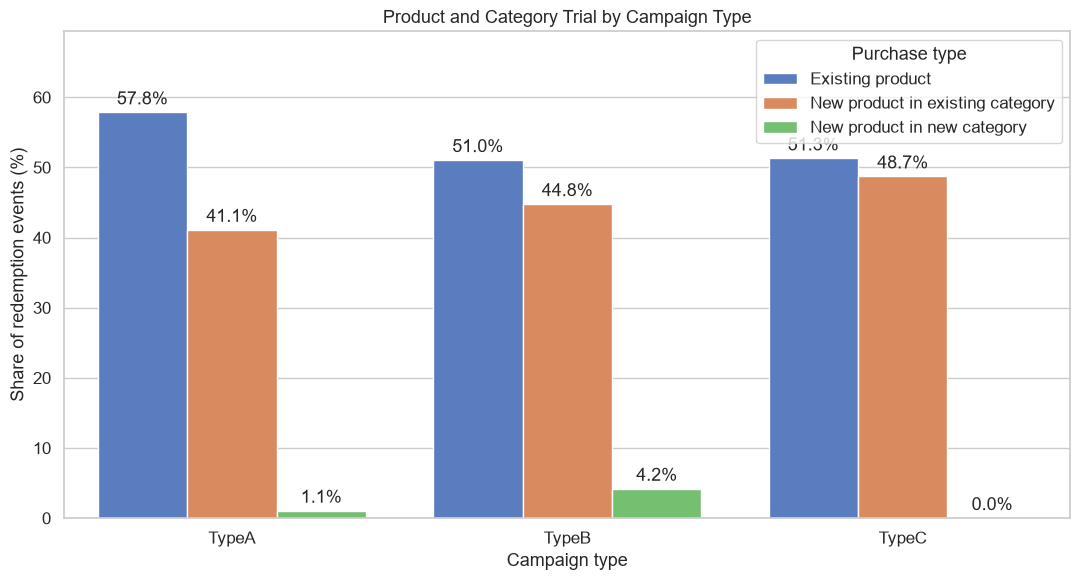

In [177]:
# Reshape purchase type distributions for visualization
purchase_type_plot = (
    purchase_type_by_campaign_pct
    .reset_index()
    .melt(
        id_vars="campaign_type",
        var_name="purchase_type",
        value_name="share_pct"
    )
)

# Visualize purchase types across campaign types
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=purchase_type_plot,
    x="campaign_type",
    y="share_pct",
    hue="purchase_type",
    hue_order=[
        "Existing product",
        "New product in existing category",
        "New product in new category"
    ],
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Product and Category Trial by Campaign Type")
plt.xlabel("Campaign type")
plt.ylabel("Share of redemption events (%)")
plt.legend(title="Purchase type")
plt.margins(y=0.2)
plt.tight_layout()
plt.show()